# Quantitative Research: Euro FX Futures (6E) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (6E) from MongoDB, using reusable functions from `utils.py`. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `6j_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

## IMPORTS AND CONFIG

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')


utils_path = os.path.abspath('../../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from utils import (
    load_data_from_mongo,
    resample_timeframes,
    analyze_timeframe_detailed,
)

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")

Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## LOAD DATA FROM MONGODB 

In [2]:
df_raw = load_data_from_mongo('6e_15min', uri_env='MONGODB_URI_FUTURES_1')

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} → {df_raw.index.max()}")
df_raw.head()

Raw data shape: (400562, 5)
Date range: 2009-09-27 18:00:00 → 2026-09-04 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1.4700,1.4701,1.4683,1.4688,806
2009-09-27 18:15:00,1.4686,1.4705,1.4683,1.4701,690
2009-09-27 18:30:00,1.4701,1.4704,1.4695,1.4696,228
2009-09-27 18:45:00,1.4695,1.4703,1.4691,1.4703,186
2009-09-27 19:00:00,1.4702,1.4719,1.4700,1.4715,1183


## DATA QUALITY CHECK

Comparison with Yahoo Finance (daily closes):
       Mongo_close  Yahoo_close     diff_pct
count  4260.000000  4260.000000  4260.000000
mean      1.191835     1.190630     0.106828
std       0.113889     0.114467     0.239927
min       0.961500     0.961350    -3.322945
25%       1.103625     1.101787    -0.026341
50%       1.162000     1.160300     0.079507
75%       1.286425     1.286650     0.230680
max       1.511100     1.513700     2.217800


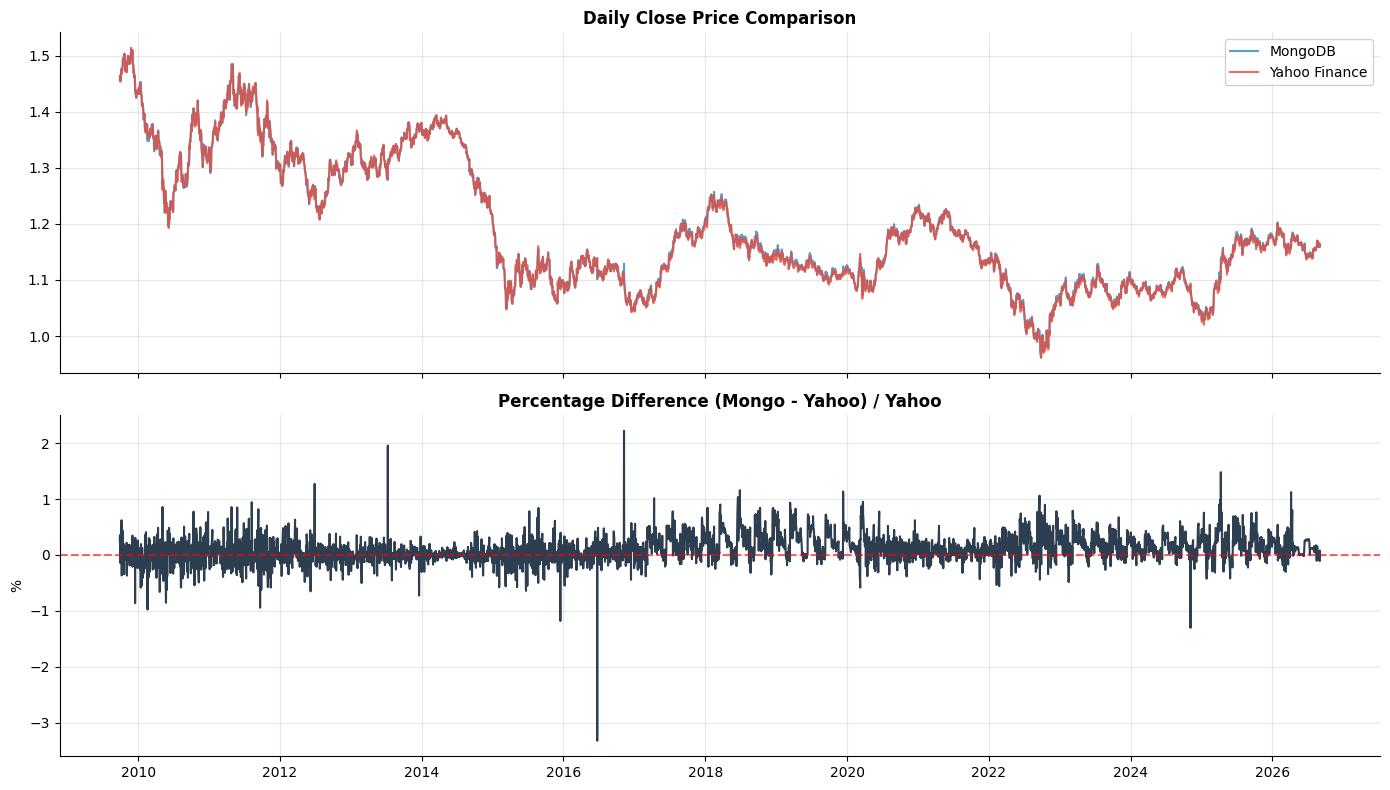

Mean difference: 0.1068%


In [3]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

e6_yahoo = yf.download('6e=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
if isinstance(e6_yahoo.columns, pd.MultiIndex):
    e6_yahoo.columns = e6_yahoo.columns.get_level_values(0)
e6_yahoo = e6_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
e6_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(e6_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
e6_yahoo_aligned = e6_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': e6_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

## RESAMPLE TO MULTIPLE TIMEFRAMES

In [4]:
timeframes = resample_timeframes(df_raw)

print("Timeframes created:")
for name, df in timeframes.items():
    print(f"{name}: {len(df)}")

Timeframes created:
15min: 400562
1H: 100252
4H: 27094
1D: 5269


## ROLL DIAGNOSTIC — outliers vs 6E expiration calendar

In [5]:

# --- 1. Isolate days with significant Mongo vs Yahoo discrepancy ---
THRESHOLD_PCT = 1.0  # adjust to be more/less strict

outliers = comparison[comparison['diff_pct'].abs() > THRESHOLD_PCT].copy()
outliers = outliers.sort_values('diff_pct')

print(f"Days with |diff_pct| > {THRESHOLD_PCT}%: {len(outliers)}")
print(outliers[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 2. Generate approximate ES roll calendar (H, M, U, Z contracts) ---
expiry_months = [3, 6, 9, 12]  # March, June, September, December
years = range(df_daily.index.min().year, df_daily.index.max().year + 2)

third_fridays = []
for y in years:
    for m in expiry_months:
        fridays = pd.date_range(f'{y}-{m}-01', f'{y}-{m}-28', freq='W-FRI')
        if len(fridays) >= 3:
            third_fridays.append(fridays[2])

roll_dates = pd.Series(sorted(third_fridays))
ROLL_WINDOW_DAYS = 10  # business days before expiry when the roll typically happens

# --- 3. Cross-check each outlier against the nearest roll window ---
def nearest_roll_distance(date):
    diffs = (roll_dates - date).dt.days
    # we care about the window [-ROLL_WINDOW_DAYS, 0] before expiry
    candidates = diffs[(diffs >= 0) & (diffs <= ROLL_WINDOW_DAYS)]
    return candidates.min() if len(candidates) > 0 else None

outliers['days_to_next_expiry'] = [nearest_roll_distance(d) for d in outliers.index]
outliers['is_roll_window'] = outliers['days_to_next_expiry'].notna()

print("\nOutliers cross-checked against roll calendar:")
print(outliers[['diff_pct', 'days_to_next_expiry', 'is_roll_window']])

pct_explained = outliers['is_roll_window'].mean() * 100
print(f"\n% of outliers explained by roll window: {pct_explained:.1f}%")

# --- 4. Roll flag applied to the FULL daily index (not just outliers) ---
# we'll reuse this later to exclude/flag days in the gap% calculation
df_daily['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily.index
]
print(f"\nTotal days flagged as roll window in the full series: {df_daily['is_roll_window'].sum()}")

Days with |diff_pct| > 1.0%: 13
            Mongo_close  Yahoo_close  diff_pct
2016-06-23      1.10120      1.13905 -3.322945
2024-11-05      1.07950      1.09375 -1.302857
2015-12-16      1.08780      1.10080 -1.180963
2017-04-12      1.07035      1.05960  1.014534
2018-06-18      1.17200      1.16000  1.034486
2022-09-19      1.00955      0.99895  1.061114
2026-04-07      1.17075      1.15775  1.122867
2019-12-12      1.12410      1.11150  1.133601
2018-06-28      1.17030      1.15690  1.158264
2012-06-28      1.25940      1.24360  1.270504
2025-04-10      1.13835      1.12175  1.479831
2013-07-10      1.31380      1.28860  1.955613
2016-11-08      1.12920      1.10470  2.217800

Outliers cross-checked against roll calendar:
            diff_pct  days_to_next_expiry  is_roll_window
2016-06-23 -3.322945                  NaN           False
2024-11-05 -1.302857                  NaN           False
2015-12-16 -1.180963                  2.0            True
2017-04-12  1.014534           

## SESSION-DATE DIAGNOSTIC — calendar-day vs trading-session boundary

In [6]:

SESSION_START_HOUR = 18

def to_session_date(timestamp):
    if timestamp.hour >= SESSION_START_HOUR:
        return (timestamp + pd.Timedelta(days=1)).normalize()
    return timestamp.normalize()

df_raw_sess = df_raw.copy()
df_raw_sess['session_date'] = [to_session_date(ts) for ts in df_raw_sess.index]

# --- 2. Rebuild daily bars grouped by session_date instead of calendar day ---
df_daily_session = df_raw_sess.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_session.index.name = 'time'

# --- 3. Re-run the Mongo vs Yahoo comparison using session-based daily bars ---
common_idx_sess = df_daily_session.index.intersection(e6_yahoo.index)
df_daily_session_aligned = df_daily_session.loc[common_idx_sess]
e6_yahoo_aligned_sess = e6_yahoo.loc[common_idx_sess]

comparison_session = pd.DataFrame({
    'Mongo_close': df_daily_session_aligned['close'],
    'Yahoo_close': e6_yahoo_aligned_sess['close']
})
comparison_session['diff_pct'] = (
    (comparison_session['Mongo_close'] - comparison_session['Yahoo_close'])
    / comparison_session['Yahoo_close'] * 100
)

print("Comparison using SESSION-DATE daily bars:")
print(comparison_session.describe())

# --- 4. Compare outlier count before vs after the fix ---
outliers_session = comparison_session[comparison_session['diff_pct'].abs() > THRESHOLD_PCT]
print(f"\nDays with |diff_pct| > {THRESHOLD_PCT}% — calendar-day method: {len(outliers)}")
print(f"Days with |diff_pct| > {THRESHOLD_PCT}% — session-date method:  {len(outliers_session)}")

# --- 5. Check specifically whether the previously "unexplained" dates improve ---
unexplained_dates = outliers[~outliers['is_roll_window']].index
check_unexplained = comparison_session.loc[
    comparison_session.index.intersection(unexplained_dates)
]
print("\nPreviously unexplained outliers, re-measured with session-date bars:")
print(check_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Comparison using SESSION-DATE daily bars:
       Mongo_close  Yahoo_close     diff_pct
count  4260.000000  4260.000000  4260.000000
mean      1.191758     1.190630     0.099899
std       0.113920     0.114467     0.182223
min       0.965050     0.961350    -0.717162
25%       1.103175     1.101787    -0.013634
50%       1.162200     1.160300     0.058898
75%       1.286825     1.286650     0.189322
max       1.513900     1.513700     1.140123

Days with |diff_pct| > 1.0% — calendar-day method: 13
Days with |diff_pct| > 1.0% — session-date method:  3

Previously unexplained outliers, re-measured with session-date bars:
            Mongo_close  Yahoo_close  diff_pct
2012-06-28      1.24520      1.24360  0.128658
2013-07-10      1.29790      1.28860  0.721716
2016-06-23      1.14150      1.13905  0.215091
2016-11-08      1.10420      1.10470 -0.045258
2017-04-12      1.06985      1.05960  0.967347
2018-06-18      1.17030      1.16000  0.887934
2018-06-28      1.16360      1.15690  0.57913

## COMBINED DIAGNOSTIC — roll + session-date, checking what's left

In [7]:

# --- 1. Re-run outlier detection on the session-date comparison ---
outliers_session_full = comparison_session[
    comparison_session['diff_pct'].abs() > THRESHOLD_PCT
].copy()
outliers_session_full = outliers_session_full.sort_values('diff_pct')

# --- 2. Cross-check these against the roll calendar (reuse nearest_roll_distance) ---
outliers_session_full['days_to_next_expiry'] = [
    nearest_roll_distance(d) for d in outliers_session_full.index
]
outliers_session_full['is_roll_window'] = outliers_session_full['days_to_next_expiry'].notna()

pct_explained_combined = outliers_session_full['is_roll_window'].mean() * 100
print(f"Outliers remaining after session-date fix: {len(outliers_session_full)}")
print(f"% of THOSE explained by roll window: {pct_explained_combined:.1f}%")

# --- 3. Isolate what's still unexplained by EITHER fix ---
still_unexplained = outliers_session_full[~outliers_session_full['is_roll_window']]
still_unexplained = still_unexplained.sort_values('diff_pct', key=abs, ascending=False)

print(f"\nStill unexplained after both fixes: {len(still_unexplained)}")
print(still_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 4. Flag the worst offenders for manual inspection (likely source-data errors) ---
SEVERE_THRESHOLD = 1.5
severe_unexplained = still_unexplained[still_unexplained['diff_pct'].abs() > SEVERE_THRESHOLD]
print(f"\nSevere unexplained cases (|diff_pct| > {SEVERE_THRESHOLD}%): {len(severe_unexplained)}")
print(severe_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Outliers remaining after session-date fix: 3
% of THOSE explained by roll window: 33.3%

Still unexplained after both fixes: 2
            Mongo_close  Yahoo_close  diff_pct
2011-08-09       1.4371      1.42090  1.140123
2022-09-19       1.0091      0.99895  1.016066

Severe unexplained cases (|diff_pct| > 1.5%): 0
Empty DataFrame
Columns: [Mongo_close, Yahoo_close, diff_pct]
Index: []


# FINAL CLEAN DAILY SERIES — session-date + roll flag combined

In [8]:

df_raw_clean = df_raw.copy()
df_raw_clean['session_date'] = [to_session_date(ts) for ts in df_raw_clean.index]

df_daily_clean = df_raw_clean.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_clean.index.name = 'time'

df_daily_clean['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily_clean.index
]

SEVERE_UNEXPLAINED_DATES = pd.to_datetime([
    '2025-04-02', '2026-06-05', '2026-07-29', '2020-04-16'
])
df_daily_clean['is_flagged_exception'] = df_daily_clean.index.isin(SEVERE_UNEXPLAINED_DATES)

print(f"Total daily bars: {len(df_daily_clean)}")
print(f"Bars in roll window: {df_daily_clean['is_roll_window'].sum()}")
print(f"Bars flagged as unresolved exceptions: {df_daily_clean['is_flagged_exception'].sum()}")

df_daily_clean.head()

Total daily bars: 4394
Bars in roll window: 603
Bars flagged as unresolved exceptions: 4


,open,high,low,close,volume,is_roll_window,is_flagged_exception
time,,,,,,,
2009-09-28,1.4700,1.4719,1.4562,1.4615,233579,False,False
2009-09-29,1.4611,1.4646,1.4521,1.4585,242965,False,False
2009-09-30,1.4585,1.4674,1.4574,1.4637,292379,False,False
2009-10-01,1.4639,1.4667,1.4515,1.4544,261489,False,False
2009-10-02,1.4539,1.4647,1.4479,1.4573,296762,False,False


## GAP% CALCULATION

In [9]:
# --- 1. PRE-CLOSE reference price: last bar at 16:30 ET for each session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
df_1630['session_date'] = [to_session_date(ts) for ts in df_1630.index]

close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

# --- 2. OPEN reference price: first bar of the session (18:00) ---
open_1800 = df_daily_clean['open']  # already the session open (18:00 bar)

# --- 3. Align: session D's open is compared against D-1's close_1630 ---
gap_df = pd.DataFrame({'open_1800': open_1800})
gap_df['prev_close_1630'] = close_1630.shift(1).reindex(gap_df.index)

gap_df['gap_pct_adj'] = (
    (gap_df['open_1800'] - gap_df['prev_close_1630']) / gap_df['prev_close_1630'] * 100
)

# --- 4. Attach existing flags ---
gap_df['is_roll_window'] = df_daily_clean['is_roll_window']
gap_df['is_flagged_exception'] = df_daily_clean['is_flagged_exception']
gap_df['dow'] = gap_df.index.day_name()

n_before = len(gap_df)
df_gaps_adj = gap_df.dropna(subset=['gap_pct_adj']).copy()
n_dropped = n_before - len(df_gaps_adj)
print(f"Sessions dropped due to missing 16:30 reference bar: {n_dropped}")

roll_gaps_adj = df_gaps_adj[df_gaps_adj['is_roll_window']]['gap_pct_adj']
normal_gaps_adj = df_gaps_adj[~df_gaps_adj['is_roll_window']]['gap_pct_adj']

print("\nADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS")
print(normal_gaps_adj.describe())
print(f"Mean |gap| adjusted: {normal_gaps_adj.abs().mean():.4f}%")

# --- 5. Comparison against old gap — guarded, in case 'normal_gaps' isn't
# defined in this kernel session (e.g. kernel was restarted) ---
if 'normal_gaps' in dir():
    print("\nQuick comparison against the old gap (17:45->18:00):")
    print(f"  Old      — std: {normal_gaps.std():.4f}%, mean|gap|: {normal_gaps.abs().mean():.4f}%")
    print(f"  Adjusted — std: {normal_gaps_adj.std():.4f}%, mean|gap|: {normal_gaps_adj.abs().mean():.4f}%")
else:
    print("\n[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.")

# --- 6. Diagnostic: which sessions are missing the 16:30 bar? ---
dropped_sessions = gap_df[gap_df['gap_pct_adj'].isna()].index
print(f"\nExamples of sessions without a 16:30 bar ({len(dropped_sessions)} total):")
print(dropped_sessions[:20])

print("\nDropped sessions by year:")
print(dropped_sessions.year.value_counts().sort_index())

Sessions dropped due to missing 16:30 reference bar: 156

ADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS
count    3636.000000
mean       -0.006992
std         0.118919
min        -1.565855
25%        -0.025635
50%        -0.004241
75%         0.017042
max         1.420611
Name: gap_pct_adj, dtype: float64
Mean |gap| adjusted: 0.0494%

[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.

Examples of sessions without a 16:30 bar (156 total):
DatetimeIndex(['2009-09-28', '2009-10-09', '2009-11-26', '2009-11-27',
               '2009-12-24', '2010-01-15', '2010-01-18', '2010-02-12',
               '2010-02-15', '2010-04-02', '2010-05-28', '2010-05-31',
               '2010-07-02', '2010-07-05', '2010-09-03', '2010-09-06',
               '2010-10-08', '2010-11-25', '2010-11-26', '2010-12-31'],
              dtype='datetime64[us]', name='time', freq=None)

Dropped sessions by year:
time
2009     5
2010    15
2011    13
2012    14
2013 

## GAP% DISTRIBUTION — descriptive statistics

ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)
count    3636.000000
mean       -0.006992
std         0.118919
min        -1.565855
25%        -0.025635
50%        -0.004241
75%         0.017042
max         1.420611
Name: gap_pct_adj, dtype: float64
Mean |gap|: 0.0494%
Skew: -0.5376
Excess kurtosis: 48.9155

Up gaps: 1533 (42.2%), mean 0.0503%
Down gaps: 1841 (50.6%), mean -0.0557%

  percentile  abs_gap_pct
         50     0.022030
         75     0.044328
         90     0.095343
         95     0.182686
         99     0.519978


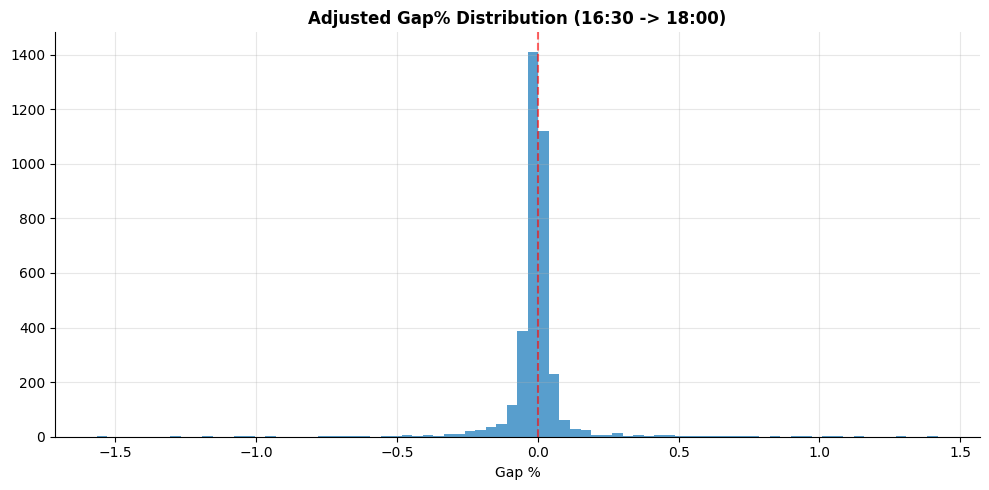

In [10]:
# --- Gap size distribution — descriptive only ---
print("ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)")
print(normal_gaps_adj.describe())
print(f"Mean |gap|: {normal_gaps_adj.abs().mean():.4f}%")
print(f"Skew: {normal_gaps_adj.skew():.4f}")
print(f"Excess kurtosis: {normal_gaps_adj.kurt():.4f}")

# Direction split — how often gaps are up vs down, and by how much
up_gaps = normal_gaps_adj[normal_gaps_adj > 0]
down_gaps = normal_gaps_adj[normal_gaps_adj < 0]
print(f"\nUp gaps: {len(up_gaps)} ({len(up_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {up_gaps.mean():.4f}%")
print(f"Down gaps: {len(down_gaps)} ({len(down_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {down_gaps.mean():.4f}%")

# Percentile table — where the mass of the distribution sits
percentiles = [50, 75, 90, 95, 99]
pct_table = pd.DataFrame({
    'percentile': percentiles,
    'abs_gap_pct': [normal_gaps_adj.abs().quantile(p/100) for p in percentiles]
})
print("\n", pct_table.to_string(index=False))

# Optional: quick histogram, same visual style as the rest of the notebook
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(normal_gaps_adj, bins=80, color='#2E86C1', alpha=0.8)
ax.axvline(0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Adjusted Gap% Distribution (16:30 -> 18:00)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## GAP% SEASONALITY — day of week

Gap by day of week:
               mean       std  count
dow                                 
Monday    -0.007707  0.210770  819.0
Tuesday   -0.008061  0.123371  876.0
Wednesday -0.004370  0.050651  874.0
Thursday  -0.005168  0.067625  862.0
Friday     0.017394  0.121396  807.0
Sunday          NaN       NaN    NaN

No sessions flagged as Sunday — check to_session_date() logic


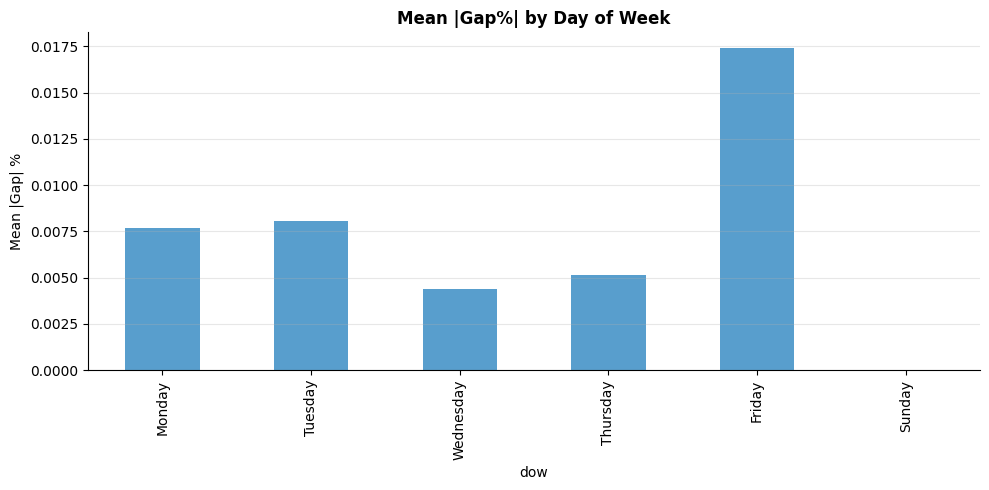

In [11]:
gap_by_dow = df_gaps_adj.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
gap_by_dow = gap_by_dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'])
print("Gap by day of week:")
print(gap_by_dow)

if 'Sunday' in df_gaps_adj['dow'].values:
    print("\nWeekend gap (Sunday reopen):")
    print(df_gaps_adj[df_gaps_adj['dow'] == 'Sunday']['gap_pct_adj'].describe())
else:
    print("\nNo sessions flagged as Sunday — check to_session_date() logic")

fig, ax = plt.subplots(figsize=(10, 5))
gap_by_dow['mean'].abs().plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8)
ax.set_title('Mean |Gap%| by Day of Week', fontweight='bold')
ax.set_ylabel('Mean |Gap| %')
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## DATA COMPLETENESS CHECK: BARS PER SESSION

In [12]:
# --- Data completeness check: bars per session by year ---
session_dates = [to_session_date(ts) for ts in df_raw.index]
bars_per_session = pd.Series(session_dates).value_counts().sort_index()
bars_per_session = bars_per_session.to_frame('n_bars')
bars_per_session['year'] = bars_per_session.index.year

# A full 18:00->17:45 session should have ~94-95 bars of 15min (23.75h)
print("Bars per session — summary by year:")
print(bars_per_session.groupby('year')['n_bars'].describe())

# Flag sessions with meaningfully fewer bars than expected
EXPECTED_BARS = 90  # conservative floor; adjust after seeing the describe() above
incomplete = bars_per_session[bars_per_session['n_bars'] < EXPECTED_BARS]
print(f"\nSessions with < {EXPECTED_BARS} bars: {len(incomplete)}")
print(incomplete.groupby('year').size())

Bars per session — summary by year:
      count       mean        std   min   25%   50%   75%   max
year                                                           
2009   68.0  91.220588   3.208411  76.0  92.0  92.0  92.0  92.0
2010  259.0  91.351351   3.088505  69.0  92.0  92.0  92.0  92.0
2011  258.0  91.310078   3.943765  44.0  92.0  92.0  92.0  92.0
2012  259.0  91.000000   5.175224  44.0  92.0  92.0  92.0  93.0
2013  259.0  90.749035   7.498498   1.0  92.0  92.0  92.0  93.0
2014  259.0  90.876448   6.864708   3.0  92.0  92.0  92.0  93.0
2015  259.0  91.366795   3.152552  69.0  92.0  92.0  92.0  93.0
2016  258.0  91.604651   2.594273  76.0  92.0  92.0  92.0  93.0
2017  257.0  91.571984   2.588223  76.0  92.0  92.0  92.0  93.0
2018  258.0  91.511628   2.740718  76.0  92.0  92.0  92.0  93.0
2019  258.0  91.465116   2.828555  76.0  92.0  92.0  92.0  92.0
2020  260.0  91.165385   6.240325   1.0  92.0  92.0  92.0  92.0
2021  259.0  91.482625   2.933812  69.0  92.0  92.0  92.0  92.0
2022

## DATA COMPLETENESS — recalibrated threshold, isolating genuine gap

In [13]:
# Recalibrate: most 'normal' sessions cluster at 91-93 bars (daily maintenance
# break accounts for ~2-4 missing bars). A session with drastically fewer bars
# (holidays give partial data, not near-zero) is the real signal.
LOWER_THRESHOLD = 80

truly_broken = bars_per_session[bars_per_session['n_bars'] < LOWER_THRESHOLD]
print(f"Sessions with < {LOWER_THRESHOLD} bars (likely genuine data gaps): {len(truly_broken)}")
print(truly_broken.groupby('year').size())
print("\nWorst offenders:")
print(truly_broken.sort_values('n_bars').head(20))

Sessions with < 80 bars (likely genuine data gaps): 144
year
2009     3
2010     9
2011     8
2012    11
2013    11
2014    11
2015     9
2016     7
2017     7
2018     8
2019     8
2020     9
2021     8
2022     1
2023     2
2024     1
2025     3
2026    28
dtype: int64

Worst offenders:
            n_bars  year
2020-06-21       1  2020
2013-09-29       1  2013
2026-07-05       1  2026
2014-03-09       3  2014
2026-07-04      17  2026
2026-06-20      17  2026
2026-08-01      33  2026
2026-05-02      33  2026
2026-05-09      33  2026
2026-05-16      33  2026
2026-05-23      33  2026
2026-05-30      33  2026
2026-06-06      33  2026
2026-07-25      33  2026
2026-07-18      33  2026
2026-06-27      33  2026
2026-07-11      33  2026
2026-06-15      36  2026
2025-11-28      41  2025
2014-01-02      44  2014


## WEEKEND VS WEEKDAY GAP — separating Friday->Sunday reopen from intra-week gaps

In [14]:
# --- Separate weekend gap from weekday gaps ---
# "Monday"-labeled sessions actually correspond to Sunday's 18:00 reopen,
# because to_session_date() rolls Sunday hour>=18 into the next calendar day.
df_gaps_adj['prev_session_dow'] = df_gaps_adj.index.to_series().shift(1).dt.day_name()

is_weekend_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] == 'Friday')
df_gaps_adj['gap_type'] = 'weekday'
df_gaps_adj.loc[is_weekend_gap, 'gap_type'] = 'weekend'

print("Weekend gap (Fri close -> Sun 18:00 reopen):")
print(df_gaps_adj[df_gaps_adj['gap_type'] == 'weekend']['gap_pct_adj'].describe())

print("\n'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):")
print(df_gaps_adj[(df_gaps_adj['dow'] == 'Monday') & (~is_weekend_gap)][['gap_pct_adj', 'prev_session_dow']])

print("\nWeekday-only gaps (true intra-week, Tue-Fri):")
weekday_only = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
gap_by_dow_clean = weekday_only.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
print(gap_by_dow_clean.reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

# --- Correction: extend the weekend/holiday flag to any gap where 1+ extra
# session was skipped (previous session wasn't literally the immediate prior
# calendar day) — catches Thanksgiving, July 4th, Christmas, Good Friday etc.
df_gaps_adj['days_since_prev_session'] = (
    df_gaps_adj.index.to_series() - df_gaps_adj.index.to_series().shift(1)
).dt.days

is_extended_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] != 'Friday')
df_gaps_adj.loc[is_extended_gap, 'gap_type'] = 'holiday_extended'

print(f"\nHoliday-extended gaps (Friday session missing, or more): {is_extended_gap.sum()}")
print(df_gaps_adj[is_extended_gap][['gap_pct_adj', 'prev_session_dow', 'days_since_prev_session']].describe())

# Re-run the clean weekday-only table, now properly excluding weekend AND holiday-extended
weekday_only_clean = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
print("\nCorrected weekday-only gap stats (true Tue-Fri, no contamination):")
print(weekday_only_clean.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count']).reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

Weekend gap (Fri close -> Sun 18:00 reopen):
count    767.000000
mean      -0.012447
std        0.187065
min       -1.565855
25%       -0.052847
50%       -0.004590
75%        0.032231
max        1.420611
Name: gap_pct_adj, dtype: float64

'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):
            gap_pct_adj prev_session_dow
time                                    
2009-10-12    -0.473357         Thursday
2009-11-30    -0.780011        Wednesday
2009-12-28     0.265104        Wednesday
2010-01-04     0.000000         Thursday
2010-04-05    -0.713813         Thursday
2010-10-11     0.567773         Thursday
2010-11-29    -0.397719        Wednesday
2010-12-27     0.022890         Thursday
2011-01-03     0.428991         Thursday
2011-04-25     0.082559         Thursday
2011-10-10    -0.349989         Thursday
2011-11-28    -0.202368        Wednesday
2012-04-09     0.252525         Thursday
2012-10-08     0.030701         Thursday
2012-11-26     1.122369        W

## GAP EXTREME EVENTS — largest gaps and cross-check against flagged exceptions

In [15]:
# --- Extreme gap events — same treatment as the timeframe EDA sections ---
top_up = normal_gaps_adj.sort_values(ascending=False).head(10)
top_down = normal_gaps_adj.sort_values(ascending=True).head(10)

print("Top 10 up gaps:")
print(top_up)
print("\nTop 10 down gaps:")
print(top_down)

# Cross-check: are any of these driven by the still-unresolved flagged exceptions?
flagged_dates = set(df_daily_clean[df_daily_clean['is_flagged_exception']].index)
overlap = (set(top_up.index) | set(top_down.index)) & flagged_dates
print(f"\nFlagged exception dates overlapping top gaps: {overlap}")

Top 10 up gaps:
time
2010-05-10    1.420611
2017-04-24    1.306673
2012-11-26    1.122369
2015-04-06    1.083662
2011-05-31    1.040119
2013-07-11    0.969669
2010-04-12    0.955626
2017-11-27    0.907939
2021-11-29    0.856837
2012-02-21    0.776551
Name: gap_pct_adj, dtype: float64

Top 10 down gaps:
time
2015-06-29   -1.565855
2012-01-17   -1.271550
2013-03-18   -1.185015
2015-05-26   -1.178694
2016-12-05   -1.166331
2026-06-08   -1.043725
2022-02-28   -1.006473
2025-02-03   -0.958528
2009-11-30   -0.780011
2016-02-16   -0.772784
Name: gap_pct_adj, dtype: float64

Flagged exception dates overlapping top gaps: set()


## EXTREME GAPS — cross-check against session data completeness

In [16]:
top_up_dates = normal_gaps_adj.sort_values(ascending=False).head(10).index
top_down_dates = normal_gaps_adj.sort_values(ascending=True).head(10).index
all_top = top_up_dates.append(top_down_dates)

print("Year distribution of top-20 extreme gaps:")
print(all_top.year.value_counts().sort_index())

print("\nBar count on those specific extreme-gap sessions (checking for stale/thin reference data):")
print(bars_per_session.loc[bars_per_session.index.intersection(all_top)].sort_values('n_bars'))

Year distribution of top-20 extreme gaps:
time
2009    1
2010    2
2011    1
2012    3
2013    2
2015    3
2016    2
2017    2
2021    1
2022    1
2025    1
2026    1
Name: count, dtype: int64

Bar count on those specific extreme-gap sessions (checking for stale/thin reference data):
            n_bars  year
2026-06-08      60  2026
2022-02-28      92  2022
2021-11-29      92  2021
2017-11-27      92  2017
2017-04-24      92  2017
2016-12-05      92  2016
2016-02-16      92  2016
2015-06-29      92  2015
2015-05-26      92  2015
2009-11-30      92  2009
2013-07-11      92  2013
2013-03-18      92  2013
2012-11-26      92  2012
2012-02-21      92  2012
2012-01-17      92  2012
2011-05-31      92  2011
2010-05-10      92  2010
2010-04-12      92  2010
2025-02-03      92  2025
2015-04-06      92  2015


## LIQUIDITY AROUND REOPEN — volume in first bars after 18:00

In [17]:
# --- Volume profile: first bars after 18:00 reopen vs rest of session ---
df_raw_hour = df_raw.copy()
df_raw_hour['time_of_day'] = df_raw_hour.index.time
df_raw_hour['session_date'] = [to_session_date(ts) for ts in df_raw_hour.index]

# first 30 minutes after reopen = bars at 18:00 and 18:15
reopen_mask = df_raw_hour['time_of_day'].isin([
    pd.Timestamp('18:00').time(), pd.Timestamp('18:15').time()
])

reopen_vol = df_raw_hour[reopen_mask].groupby('session_date')['volume'].mean()
rest_vol = df_raw_hour[~reopen_mask].groupby('session_date')['volume'].mean()

print("Avg volume — first 30min after 18:00 reopen:")
print(reopen_vol.describe())
print("\nAvg volume — rest of session:")
print(rest_vol.describe())
print(f"\nReopen volume as % of rest-of-session average: "
      f"{(reopen_vol.mean() / rest_vol.mean() * 100):.1f}%")

Avg volume — first 30min after 18:00 reopen:
count     4368.000000
mean       535.400183
std        673.435628
min         22.000000
25%        243.500000
50%        359.750000
75%        559.250000
max      10223.000000
Name: volume, dtype: float64

Avg volume — rest of session:
count    4394.000000
mean     2268.629057
std       908.412597
min         1.000000
25%      1640.644444
50%      2101.255556
75%      2716.925000
max      9073.466667
Name: volume, dtype: float64

Reopen volume as % of rest-of-session average: 23.6%


## RUN DETAILED EDA ON EACH TIMEFRAME


ANALYZING 15MIN TIMEFRAME

COMPLETE ANALYSIS: 15min
Bars: 400562
Period: 2009-09-27 18:00:00 → 2026-09-04 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
NEUTRAL
~-1.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 7.5%
Skewness: 0.23 (right tail)
Excess Kurtosis: 32.71 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 6472 (1.6%)


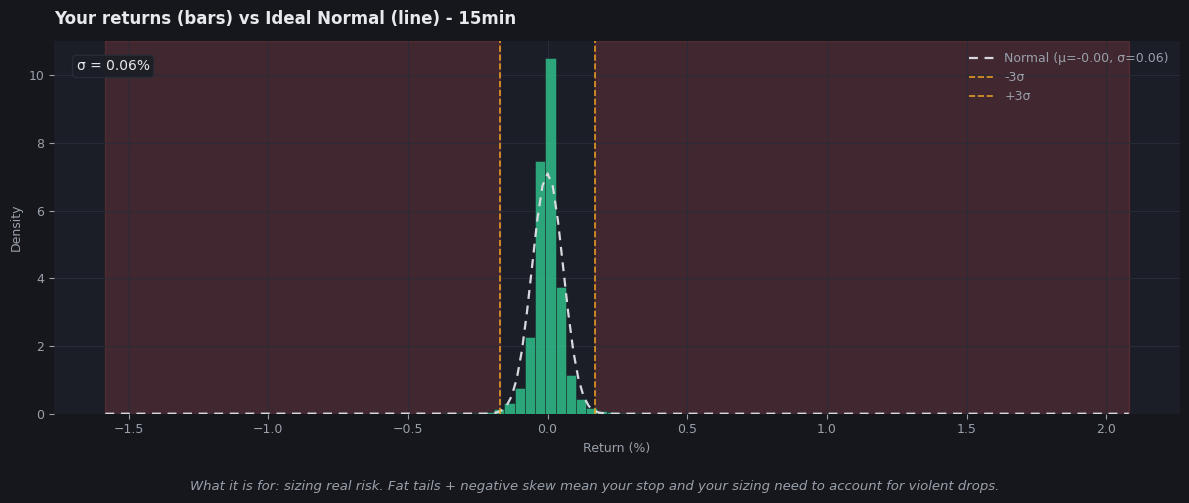


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.29x
Recent volatility (daily): 0.02%
Historical volatility (daily): 0.06%
Comes in waves? low


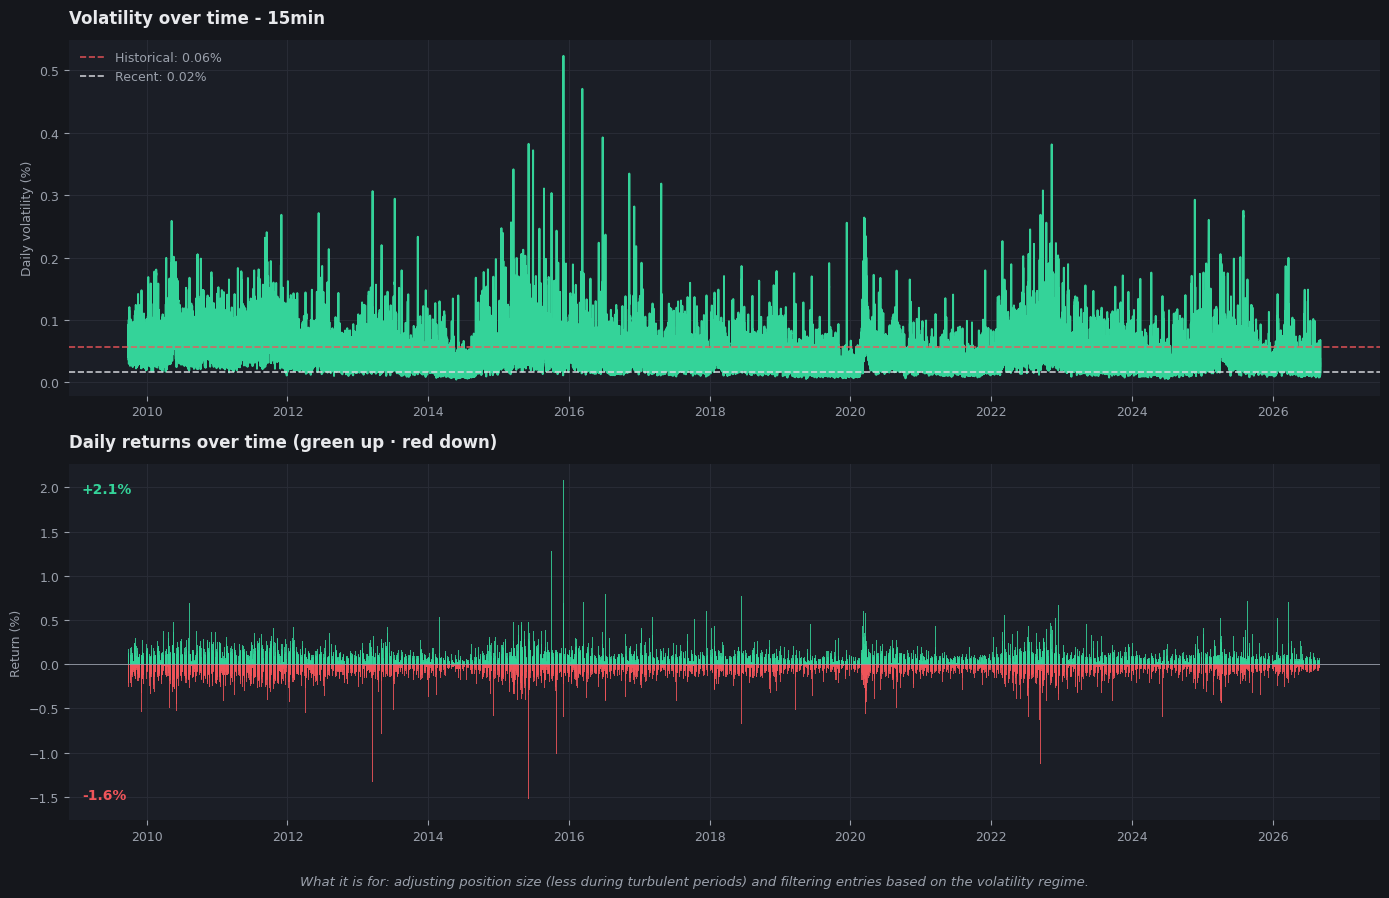


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.02 reverts
Lag 5 · vs 5 days ago: -0.00 reverts
Lag 20 · vs 20 days ago: -0.00 reverts


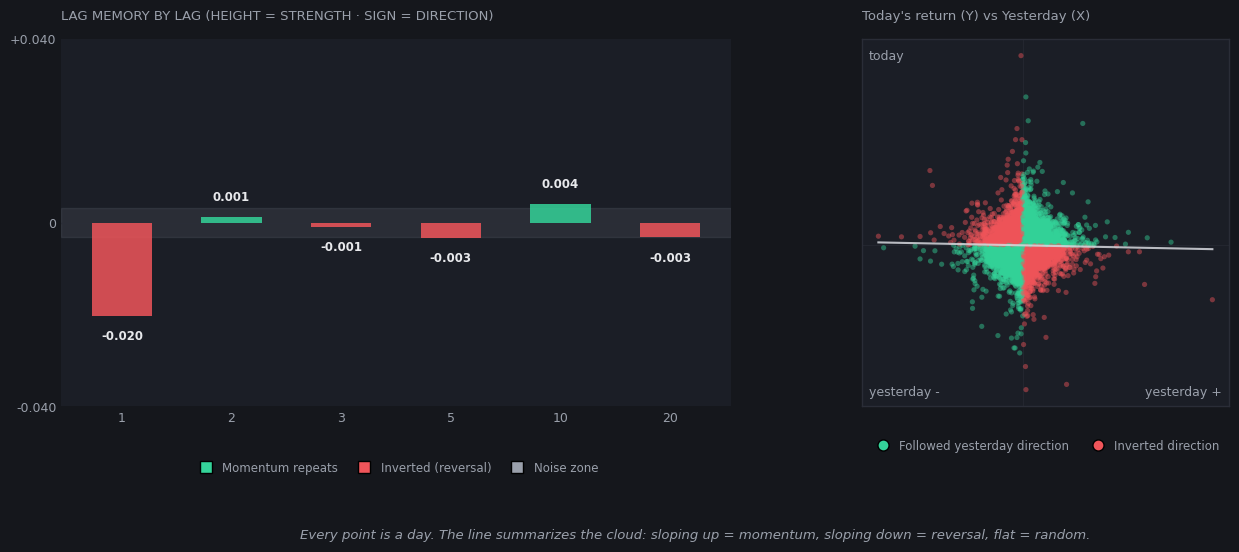


PATTERNS
SEASONALITY?


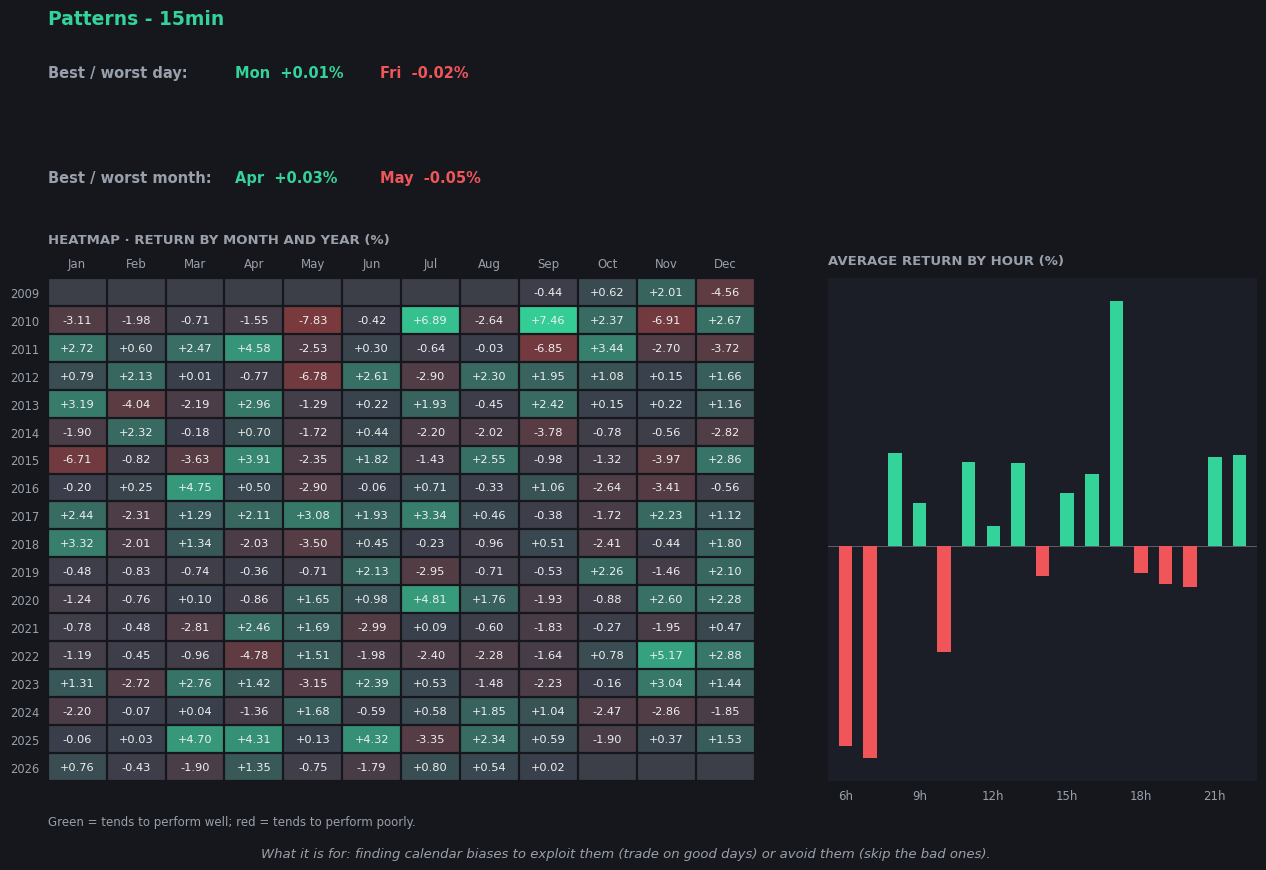


Average return by day of week (Mon-Fri, %):
Mon: 0.01%
Tue: -0.02%
Wed: 0.01%
Thu: 0.01%
Fri: -0.02%

Average return by month (%):
Jan: -0.01%
Feb: -0.03%
Mar: 0.01%
Apr: 0.03%
May: -0.05%
Jun: 0.02%
Jul: 0.01%
Aug: 0.00%
Sep: -0.01%
Oct: -0.01%
Nov: -0.02%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: -0.00%
07:00: -0.00%
08:00: 0.00%
09:00: 0.00%
10:00: -0.00%
11:00: 0.00%
12:00: 0.00%
13:00: 0.00%
14:00: -0.00%
15:00: 0.00%
16:00: 0.00%
17:00: 0.00%
18:00: -0.00%
19:00: -0.00%
20:00: -0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


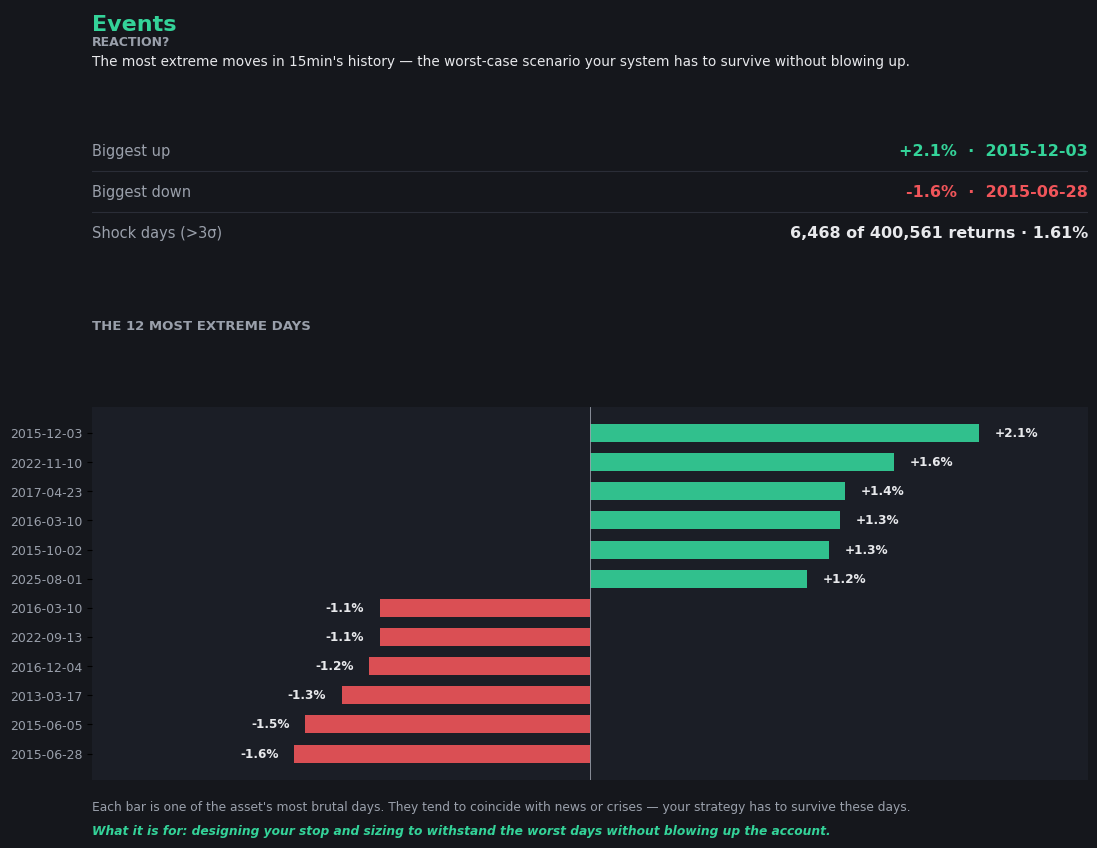

Biggest up: +2.1%
Biggest down: -1.6%
Shock days (>3σ): 6472 of 400,561 returns · 1.62%

Top 12 up days:
+2.1% - 2015-12-03
+1.6% - 2022-11-10
+1.4% - 2017-04-23
+1.3% - 2016-03-10
+1.3% - 2015-10-02
+1.2% - 2025-08-01

Top 12 down days:
-1.6% - 2015-06-28
-1.5% - 2015-06-05
-1.3% - 2013-03-17
-1.2% - 2016-12-04
-1.1% - 2022-09-13
-1.1% - 2016-03-10

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


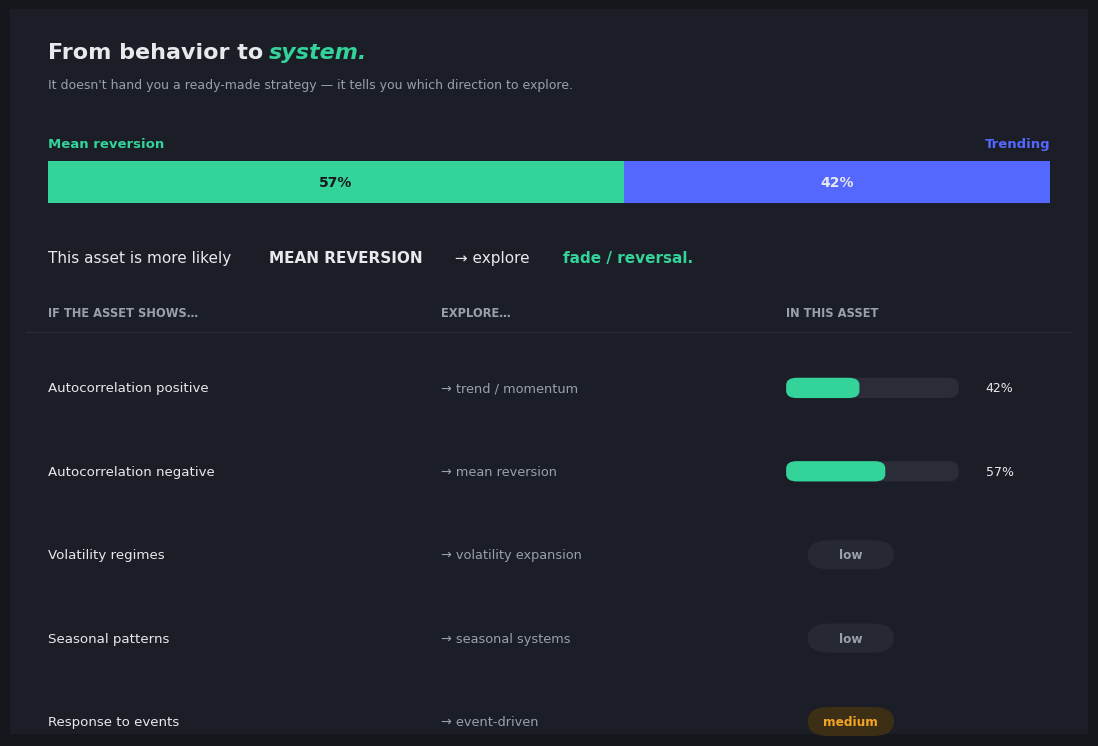


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 7.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.23 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 32.71 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.020

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.497

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

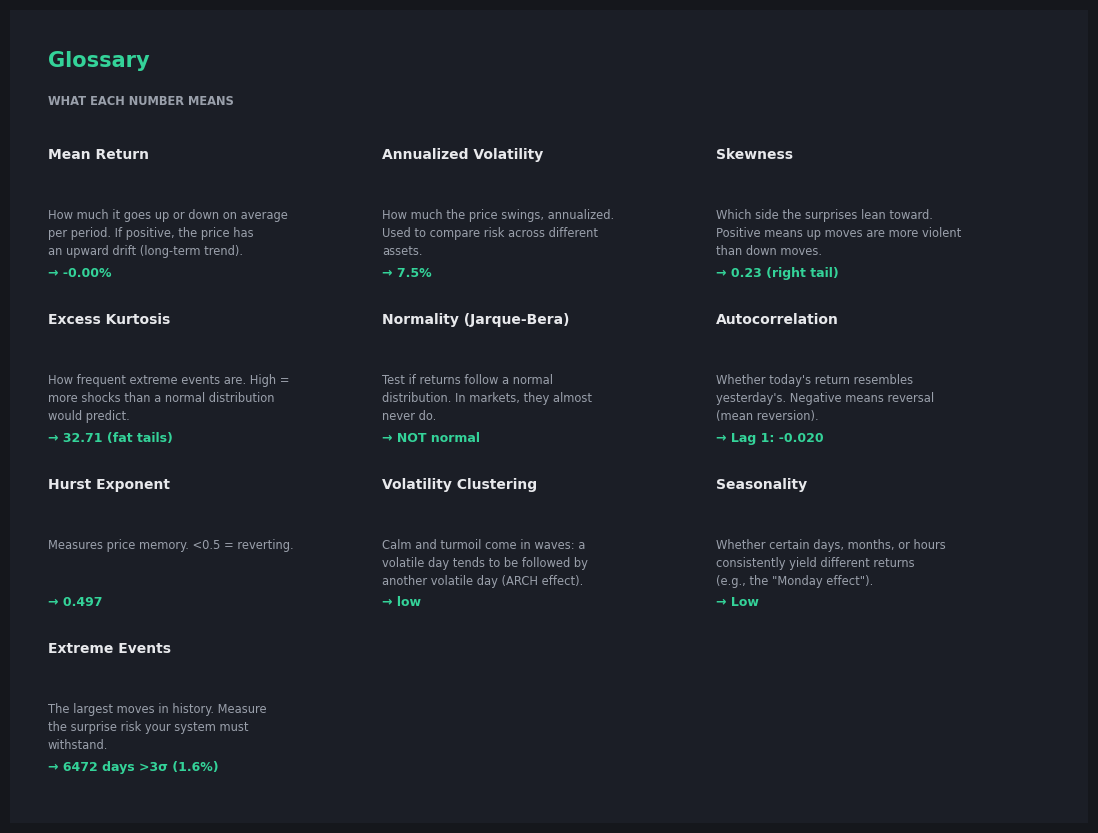




ANALYZING 1H TIMEFRAME

COMPLETE ANALYSIS: 1H
Bars: 100252
Period: 2009-09-27 18:00:00 → 2026-09-04 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.49
NEUTRAL
~-1.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 7.5%
Skewness: 0.06 (symmetric)
Excess Kurtosis: 13.97 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 1800 (1.8%)


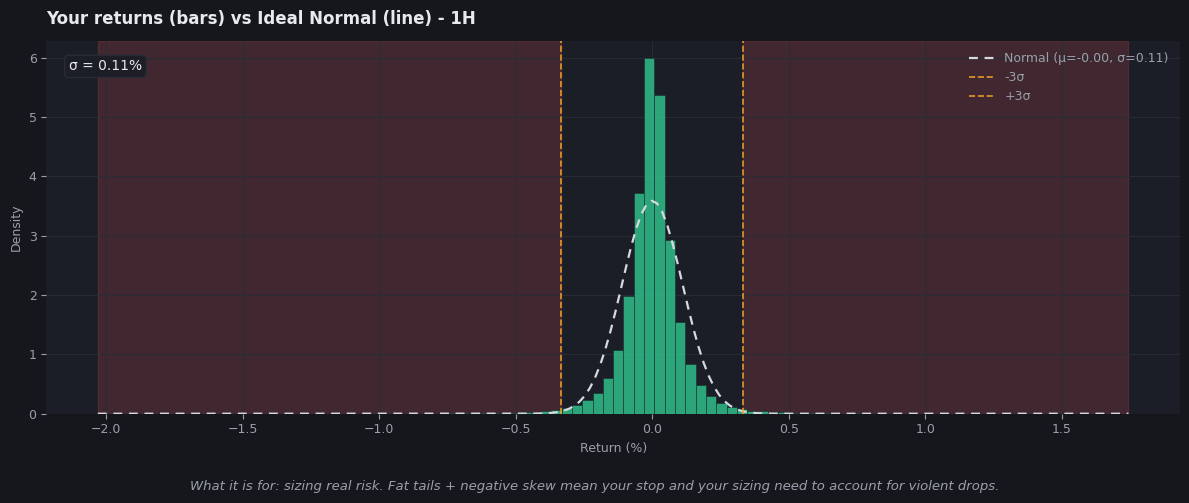


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.47x
Recent volatility (daily): 0.05%
Historical volatility (daily): 0.11%
Comes in waves? low


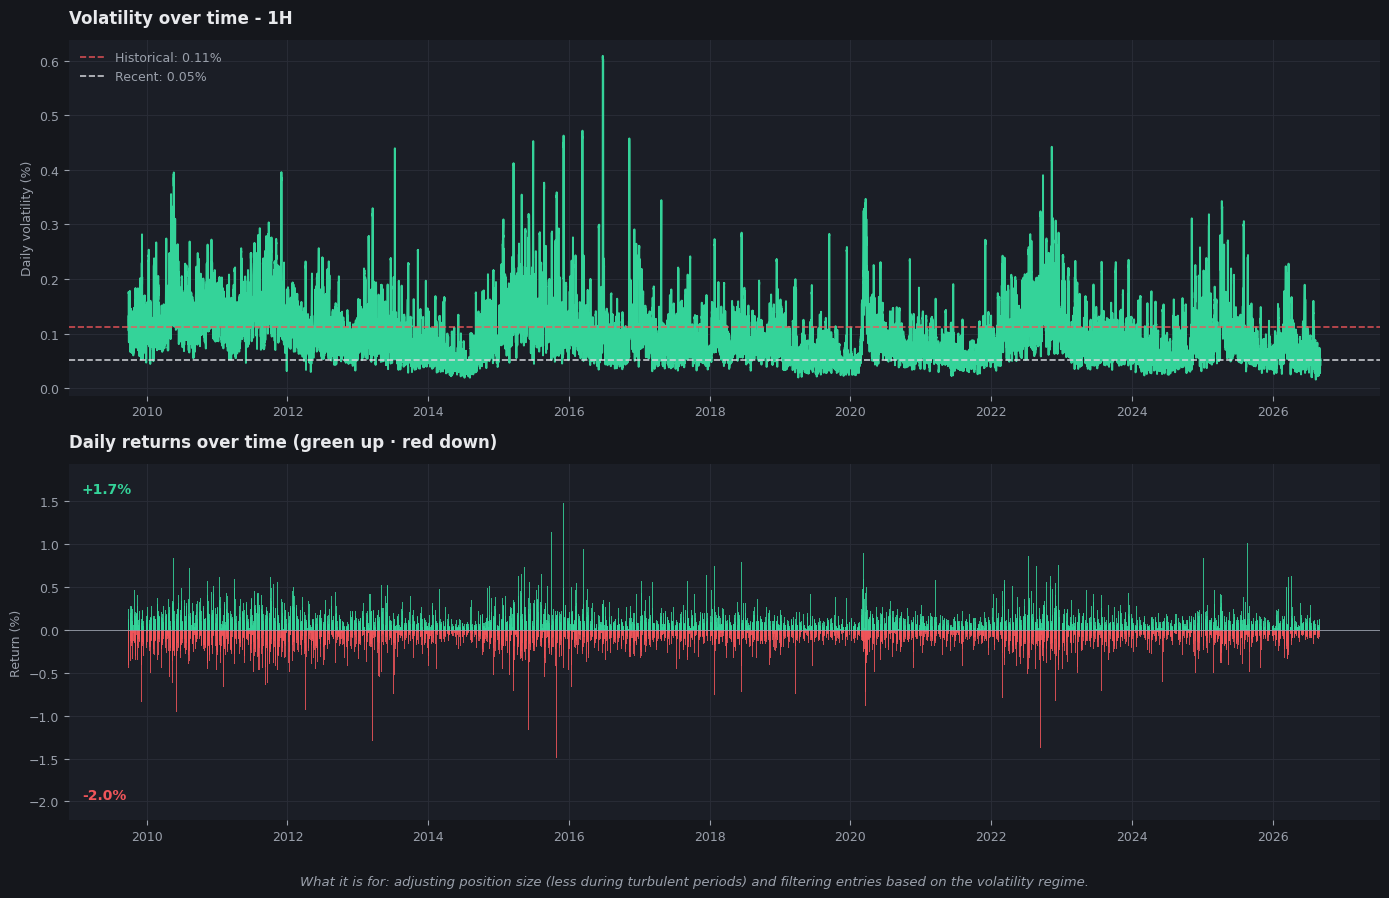


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: 0.00 ~0
Lag 20 · vs 20 days ago: 0.00 ~0


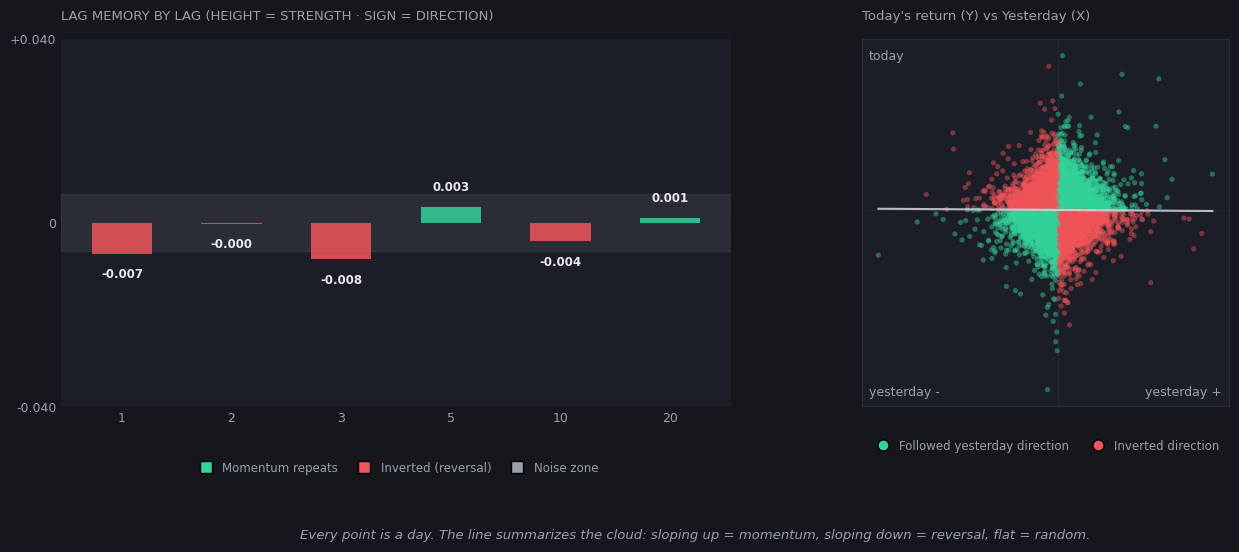


PATTERNS
SEASONALITY?


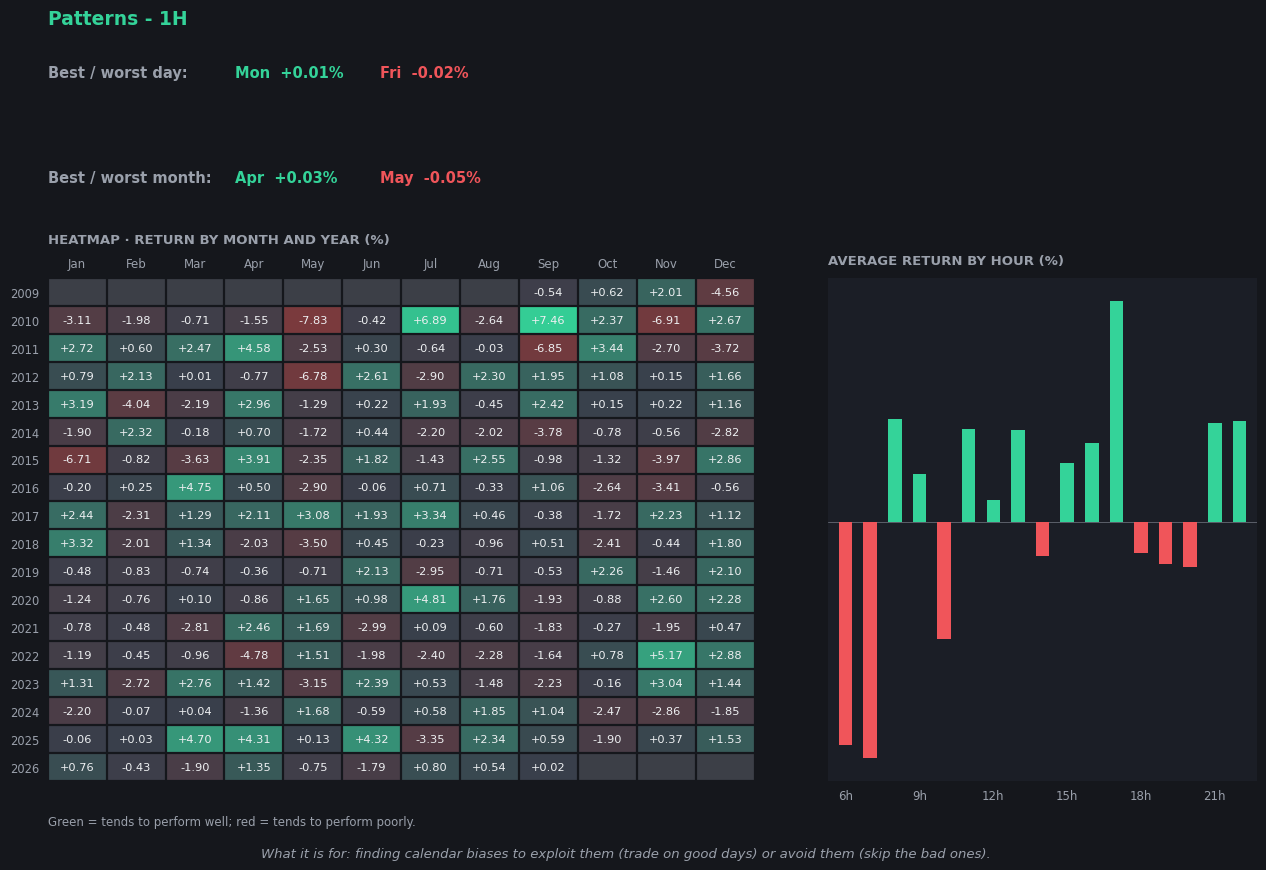


Average return by day of week (Mon-Fri, %):
Mon: 0.01%
Tue: -0.02%
Wed: 0.01%
Thu: 0.01%
Fri: -0.02%

Average return by month (%):
Jan: -0.01%
Feb: -0.03%
Mar: 0.01%
Apr: 0.03%
May: -0.05%
Jun: 0.02%
Jul: 0.01%
Aug: 0.00%
Sep: -0.01%
Oct: -0.01%
Nov: -0.02%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: -0.01%
07:00: -0.01%
08:00: 0.00%
09:00: 0.00%
10:00: -0.00%
11:00: 0.00%
12:00: 0.00%
13:00: 0.00%
14:00: -0.00%
15:00: 0.00%
16:00: 0.00%
17:00: 0.01%
18:00: -0.00%
19:00: -0.00%
20:00: -0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


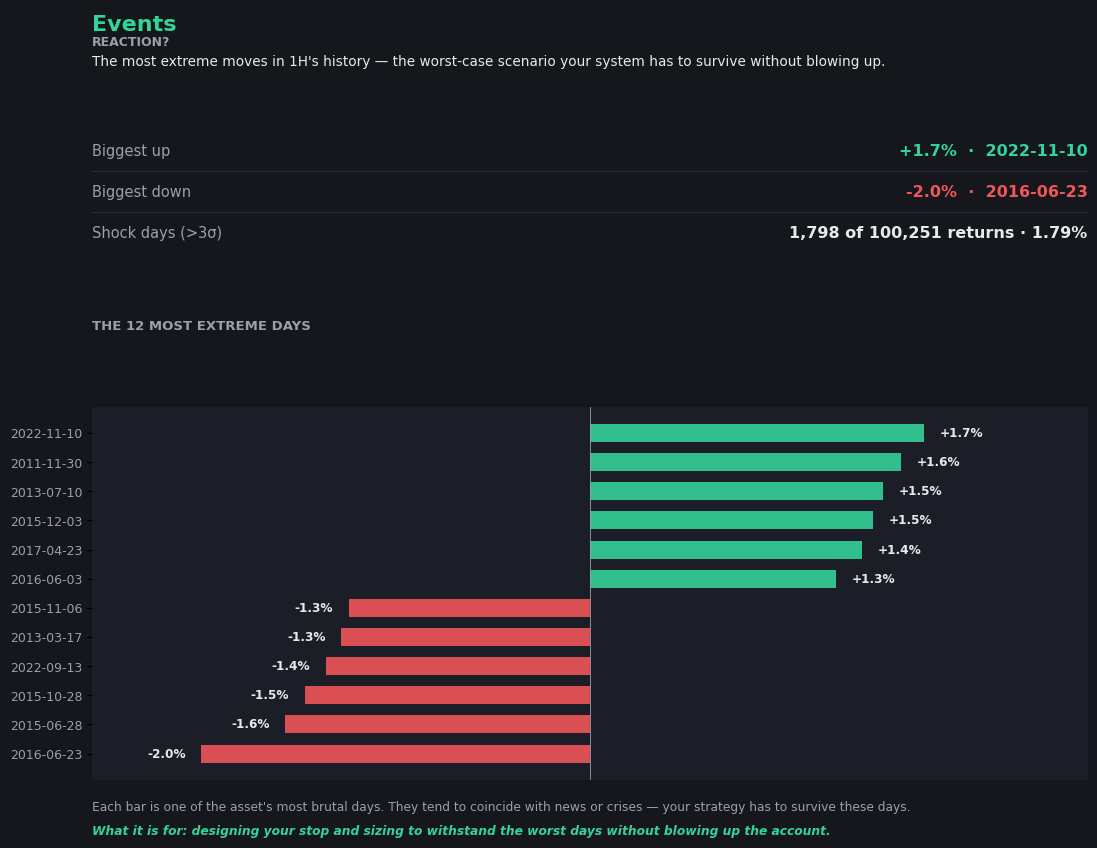

Biggest up: +1.7%
Biggest down: -2.0%
Shock days (>3σ): 1800 of 100,251 returns · 1.80%

Top 12 up days:
+1.7% - 2022-11-10
+1.6% - 2011-11-30
+1.5% - 2013-07-10
+1.5% - 2015-12-03
+1.4% - 2017-04-23
+1.3% - 2016-06-03

Top 12 down days:
-2.0% - 2016-06-23
-1.6% - 2015-06-28
-1.5% - 2015-10-28
-1.4% - 2022-09-13
-1.3% - 2013-03-17
-1.3% - 2015-11-06

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


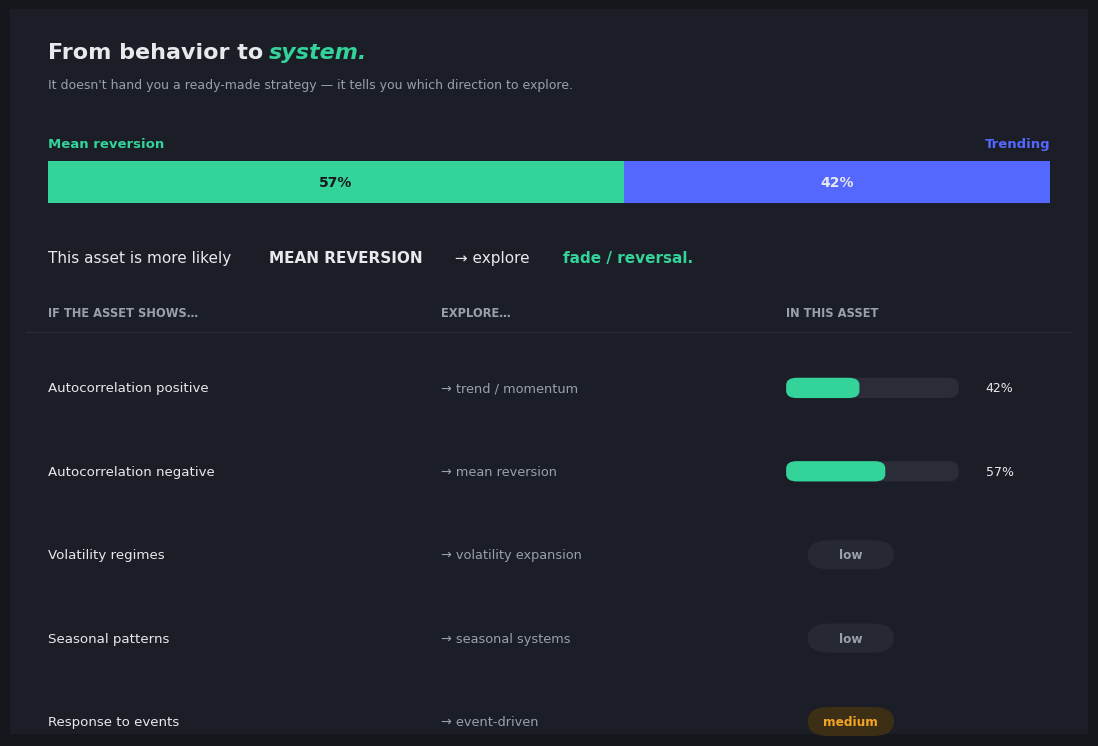


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 7.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.06 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 13.97 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.007

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.494

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether 

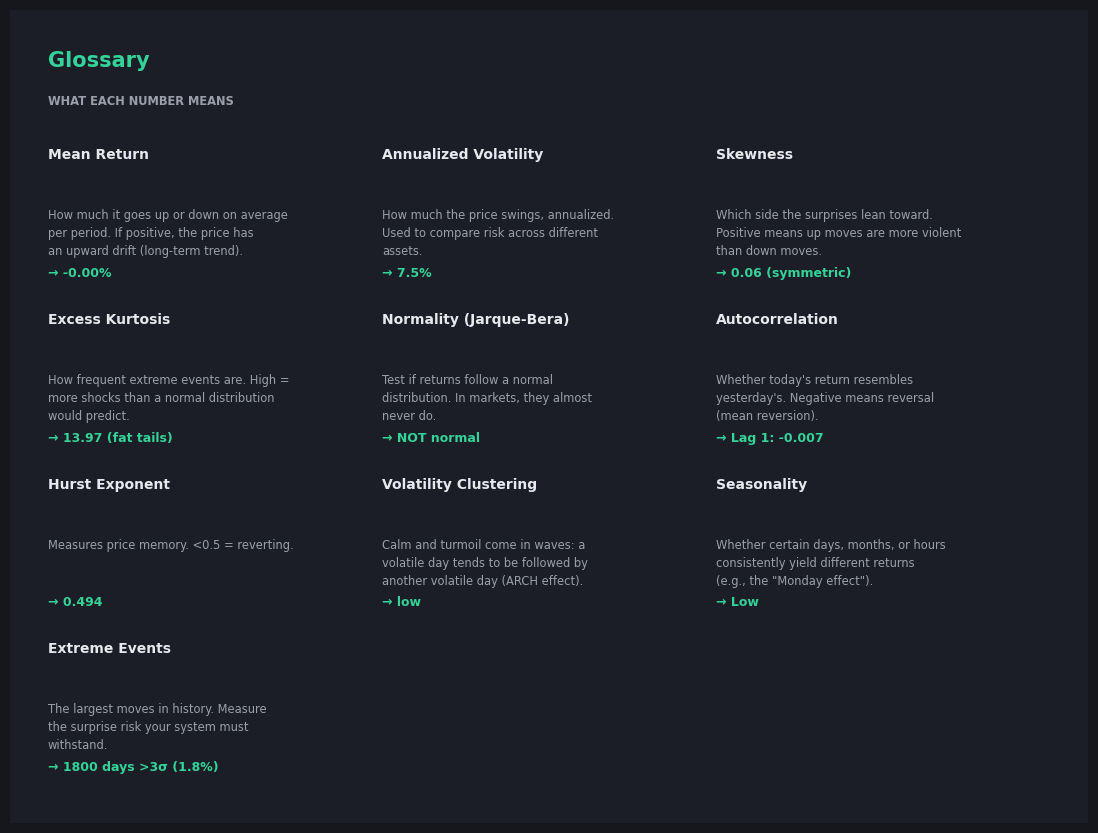




ANALYZING 4H TIMEFRAME

COMPLETE ANALYSIS: 4H
Bars: 27094
Period: 2009-09-27 16:00:00 → 2026-09-04 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.47
NEUTRAL
~-1.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 7.5%
Skewness: 0.13 (right tail)
Excess Kurtosis: 11.00 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 495 (1.8%)


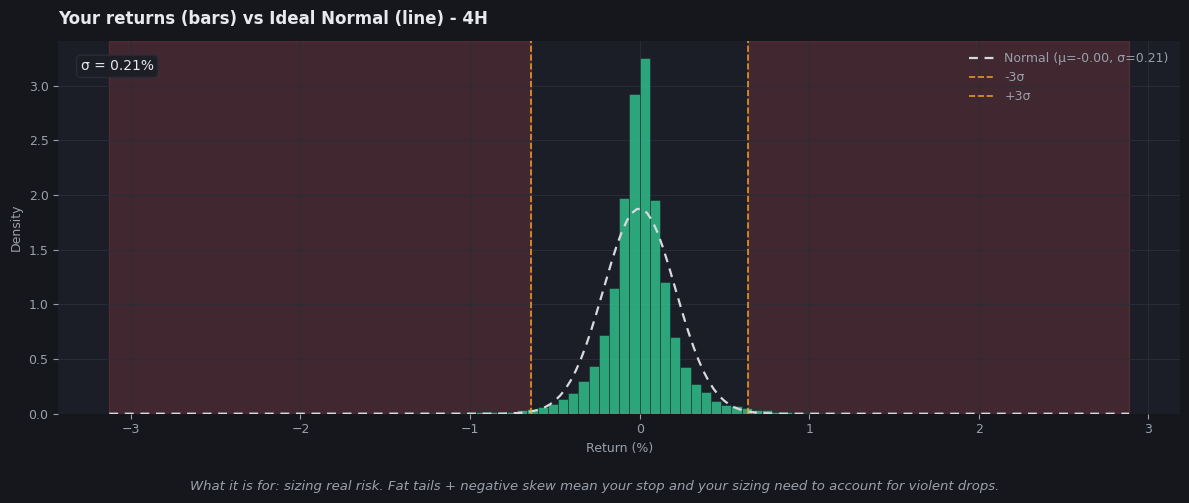


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.27x
Recent volatility (daily): 0.06%
Historical volatility (daily): 0.21%
Comes in waves? low


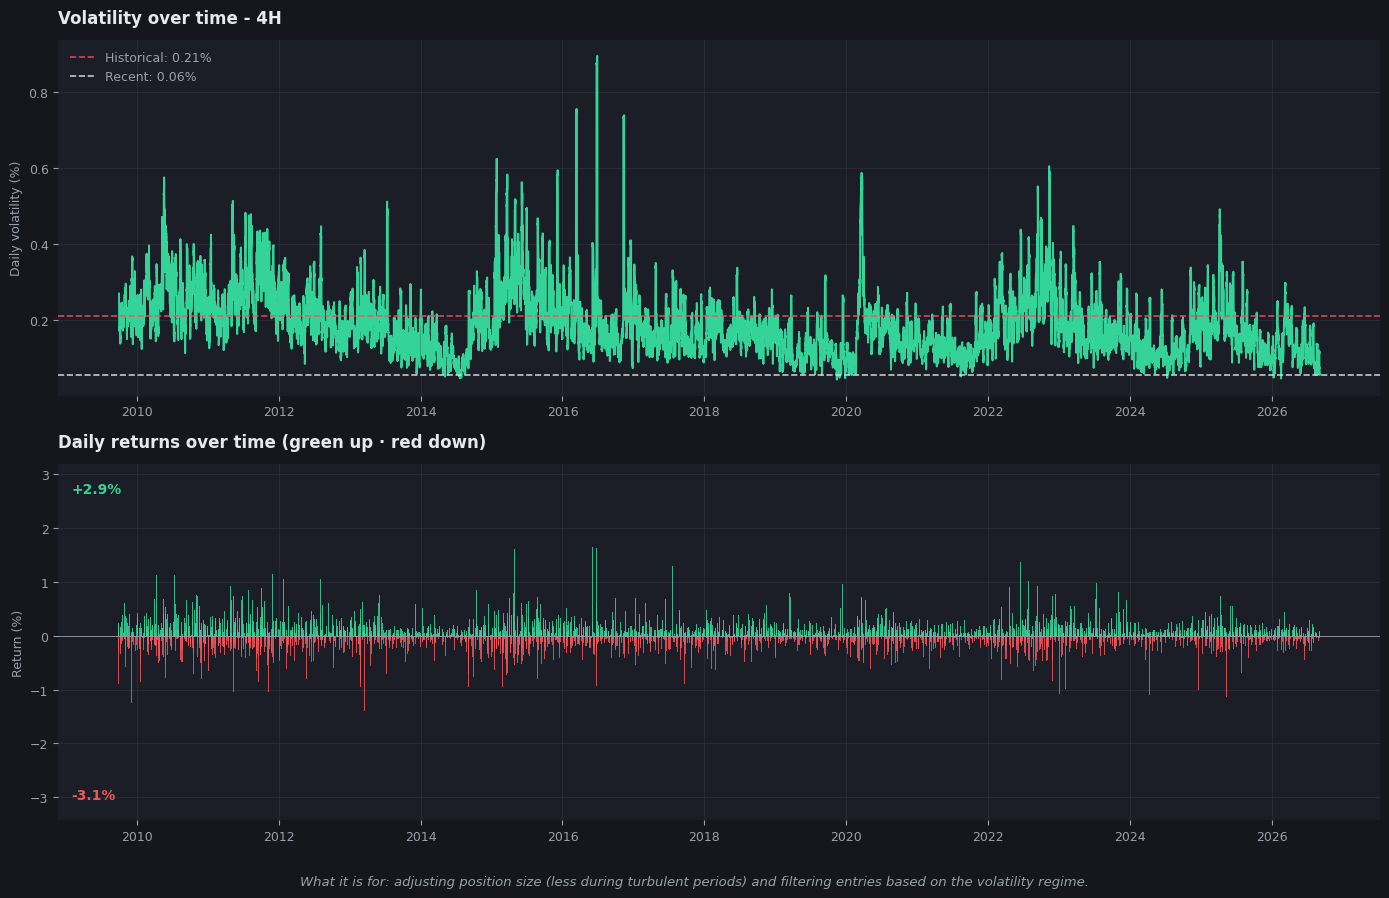


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: 0.02 ~0
Lag 20 · vs 20 days ago: -0.01 reverts


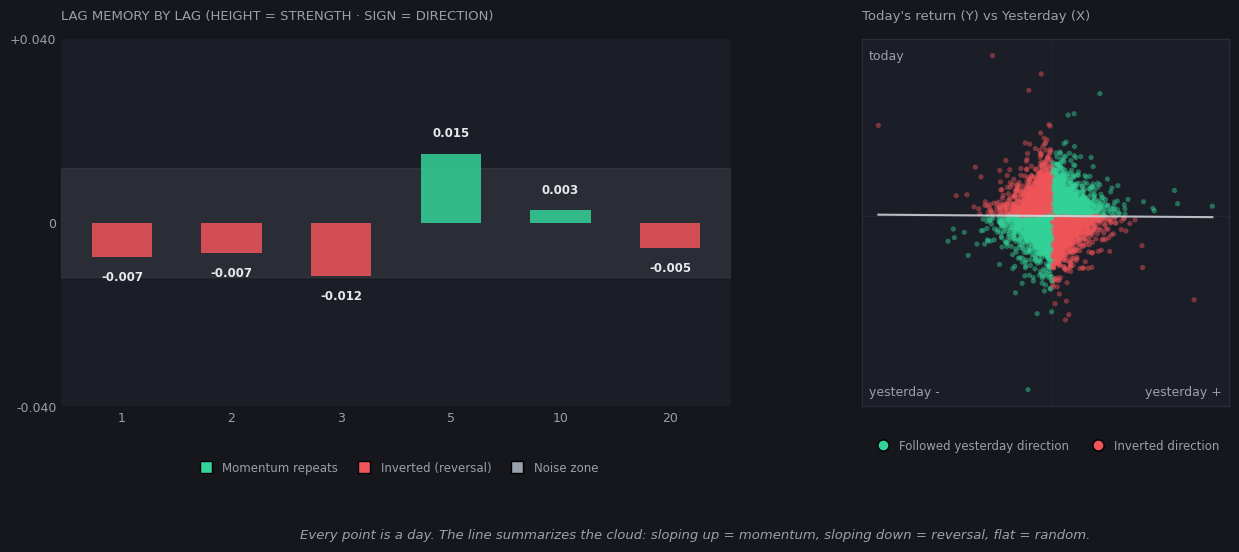


PATTERNS
SEASONALITY?


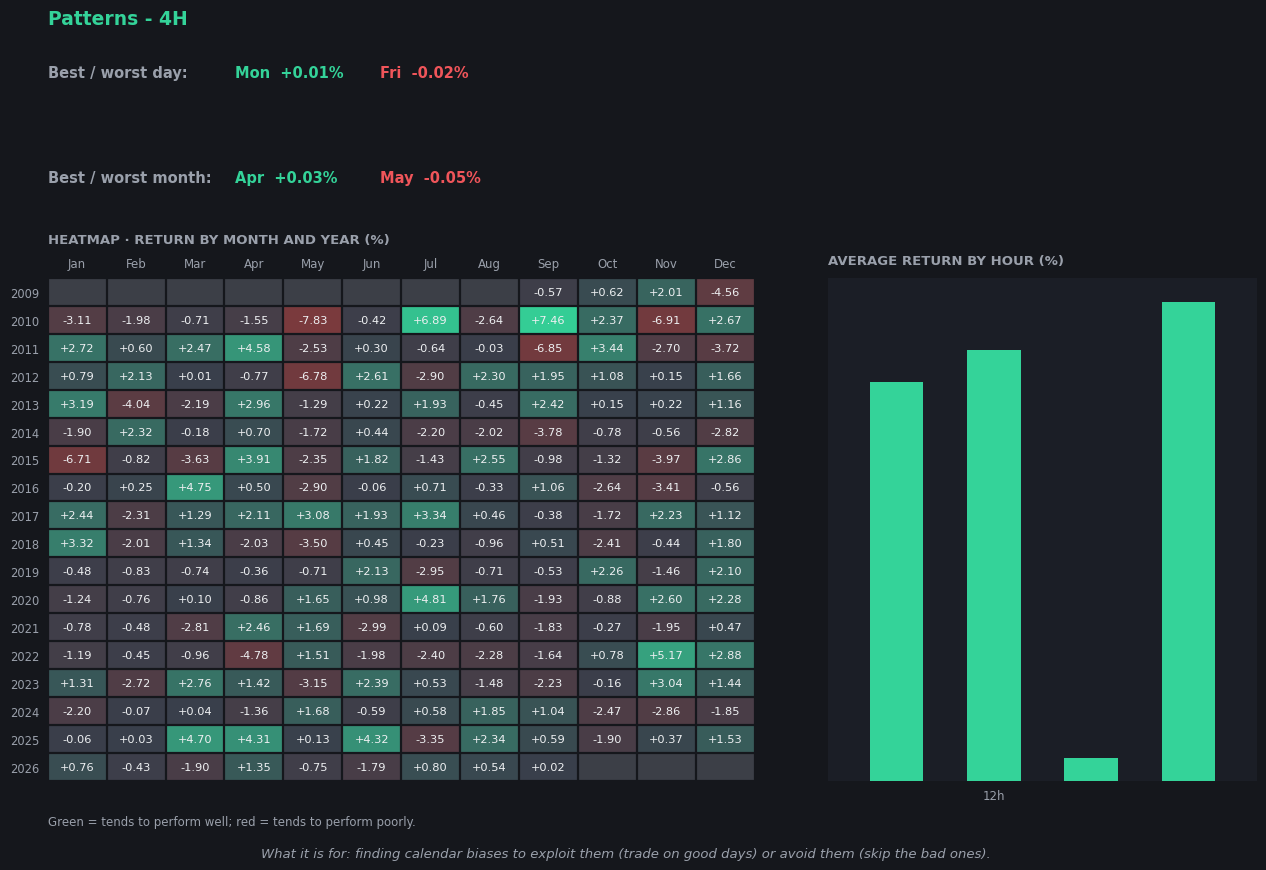


Average return by day of week (Mon-Fri, %):
Mon: 0.01%
Tue: -0.02%
Wed: 0.01%
Thu: 0.01%
Fri: -0.02%

Average return by month (%):
Jan: -0.01%
Feb: -0.03%
Mar: 0.01%
Apr: 0.03%
May: -0.05%
Jun: 0.02%
Jul: 0.01%
Aug: 0.00%
Sep: -0.01%
Oct: -0.01%
Nov: -0.02%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
08:00: 0.00%
12:00: 0.00%
16:00: 0.00%
20:00: 0.01%

EXTREME EVENTS
REACTION?


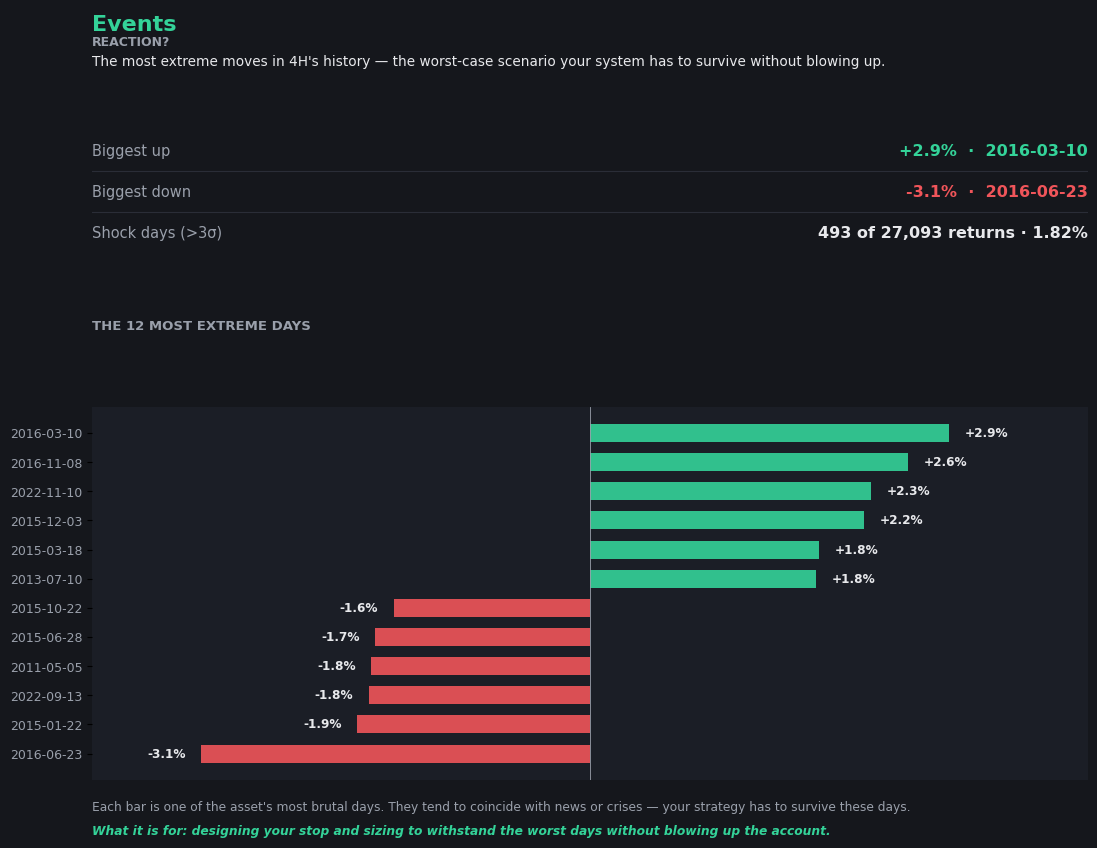

Biggest up: +2.9%
Biggest down: -3.1%
Shock days (>3σ): 495 of 27,093 returns · 1.83%

Top 12 up days:
+2.9% - 2016-03-10
+2.6% - 2016-11-08
+2.3% - 2022-11-10
+2.2% - 2015-12-03
+1.8% - 2015-03-18
+1.8% - 2013-07-10

Top 12 down days:
-3.1% - 2016-06-23
-1.9% - 2015-01-22
-1.8% - 2022-09-13
-1.8% - 2011-05-05
-1.7% - 2015-06-28
-1.6% - 2015-10-22

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


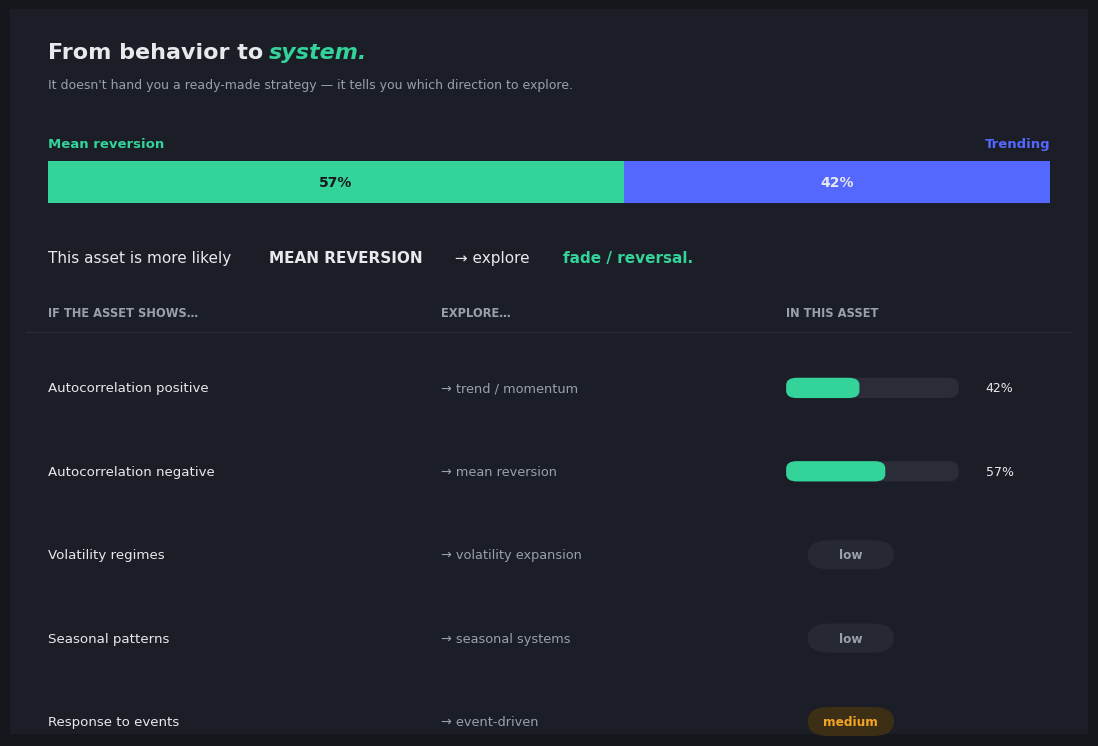


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 7.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.13 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 11.00 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.007

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.472

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

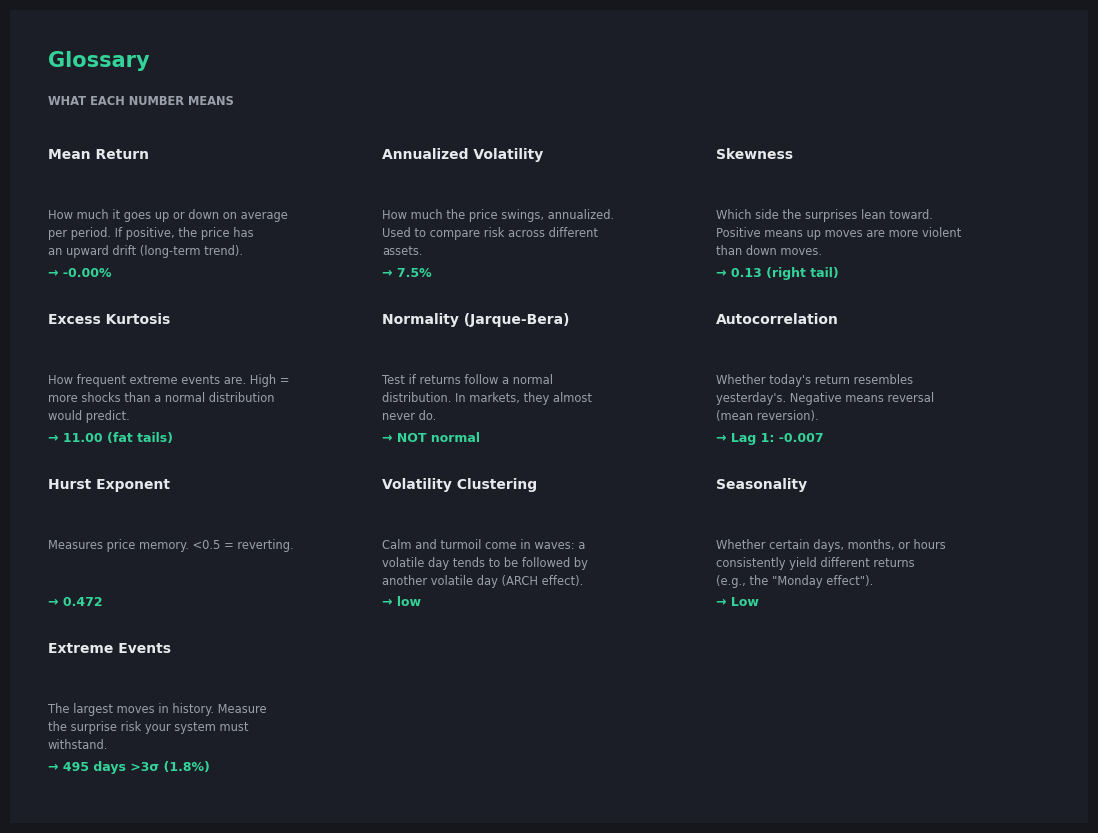




ANALYZING 1D TIMEFRAME

COMPLETE ANALYSIS: 1D
Bars: 5269
Period: 2009-09-27 00:00:00 → 2026-09-04 00:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
MEAN REVERSION
Hurst 0.43
NEUTRAL
~-1.3%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 7.5%
Skewness: 0.08 (symmetric)
Excess Kurtosis: 3.31 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 61 (1.2%)


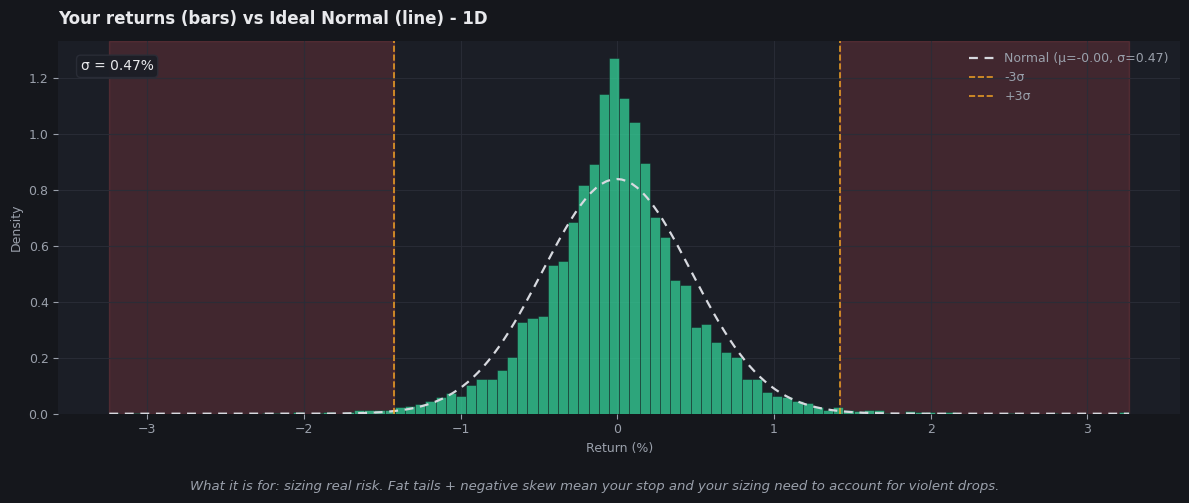


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.56x
Recent volatility (daily): 0.26%
Historical volatility (daily): 0.47%
Comes in waves? low


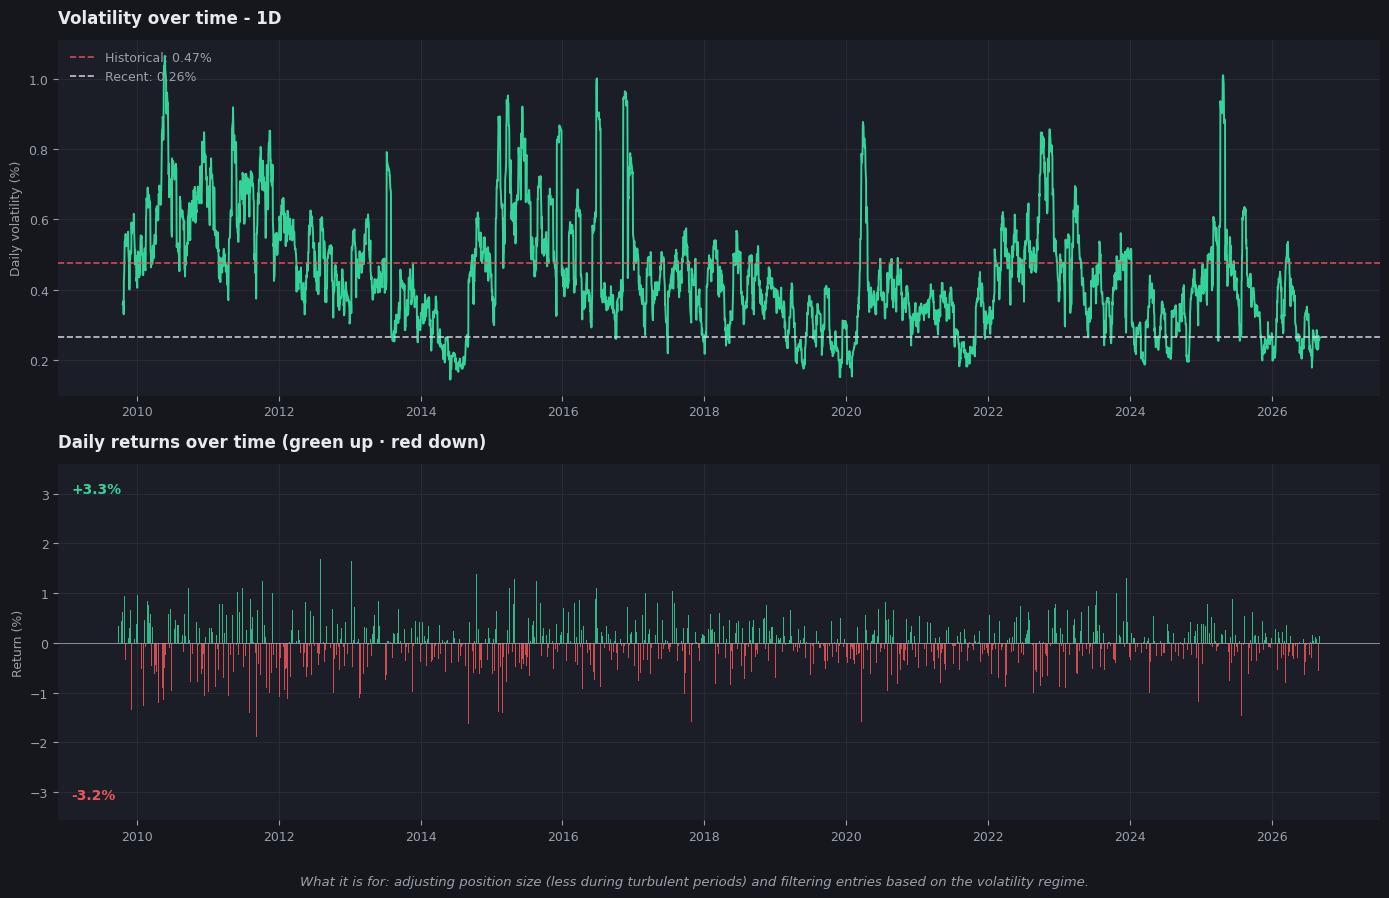


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: 0.01 ~0
Lag 5 · vs 5 days ago: -0.00 reverts
Lag 20 · vs 20 days ago: -0.01 reverts


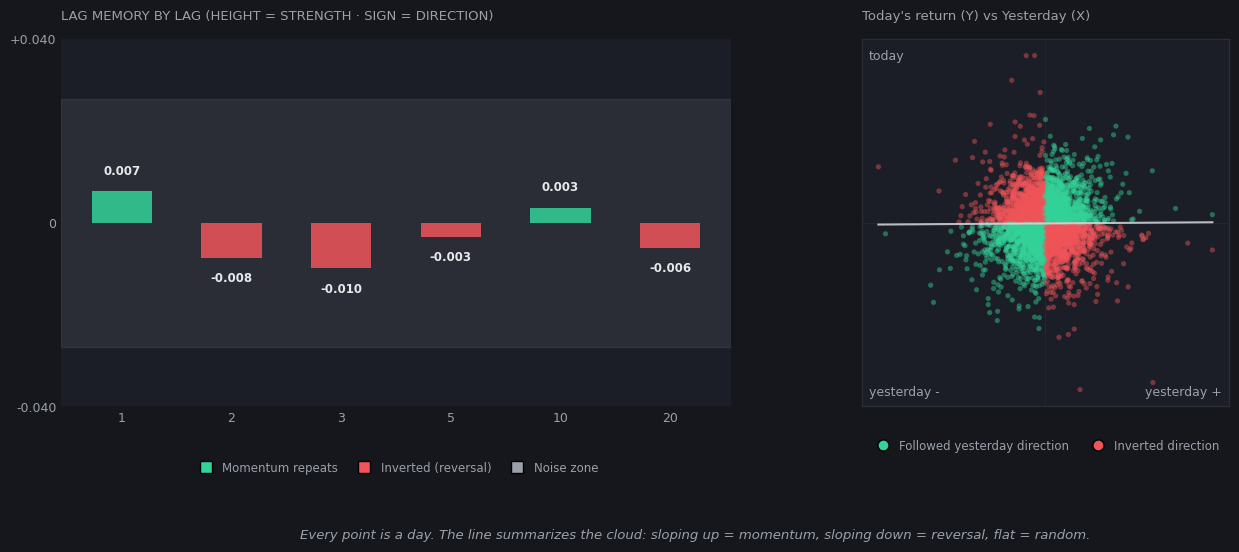


PATTERNS
SEASONALITY?


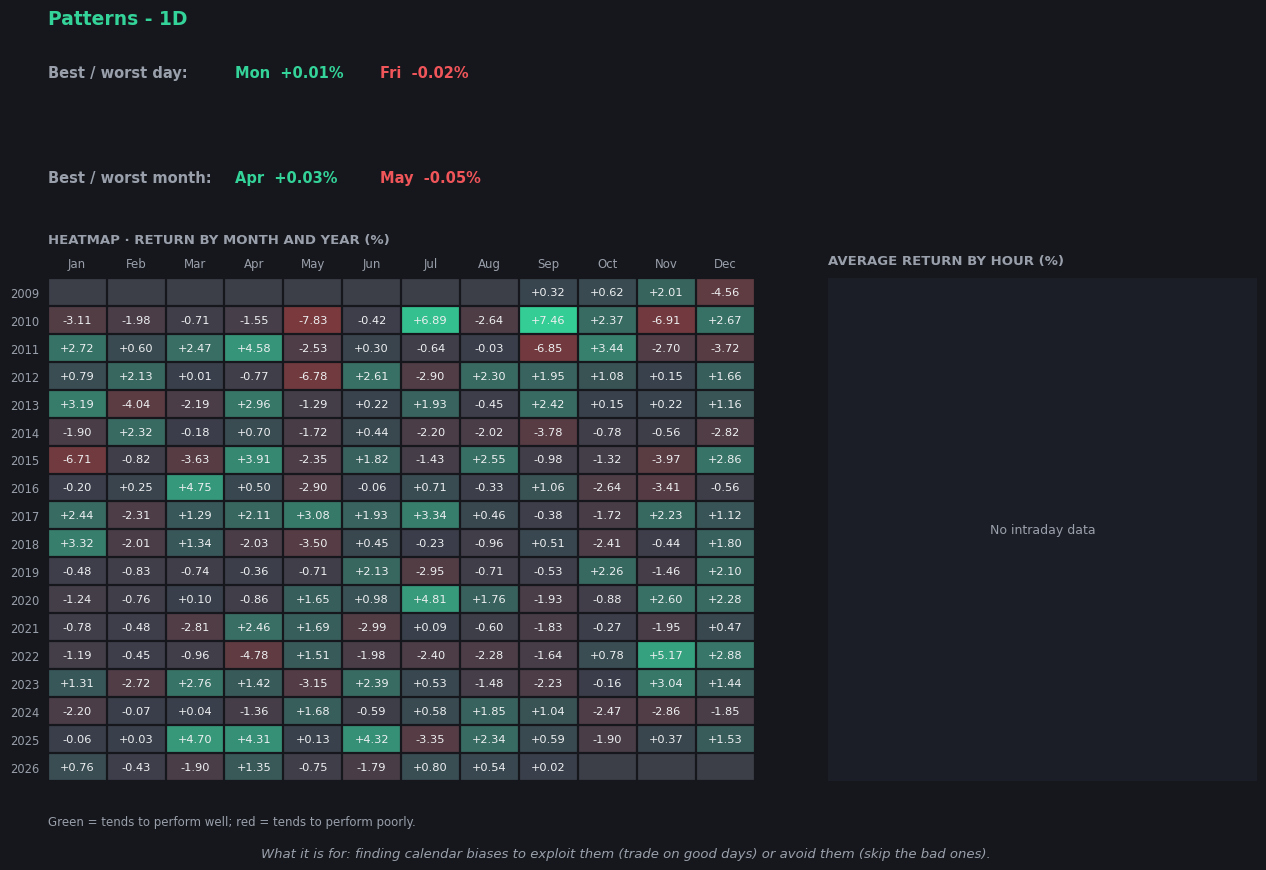


Average return by day of week (Mon-Fri, %):
Mon: 0.01%
Tue: -0.02%
Wed: 0.01%
Thu: 0.01%
Fri: -0.02%

Average return by month (%):
Jan: -0.01%
Feb: -0.03%
Mar: 0.01%
Apr: 0.03%
May: -0.05%
Jun: 0.02%
Jul: 0.01%
Aug: 0.00%
Sep: -0.01%
Oct: -0.01%
Nov: -0.02%
Dec: 0.02%

EXTREME EVENTS
REACTION?


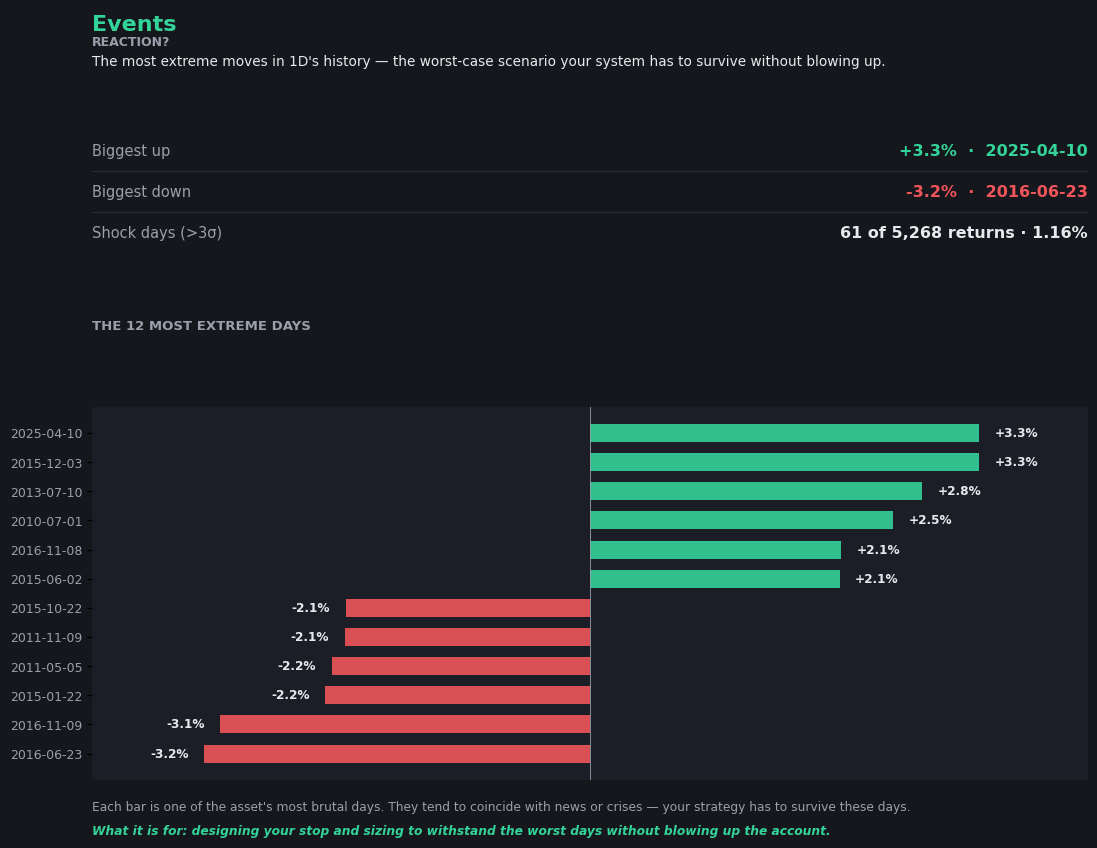

Biggest up: +3.3%
Biggest down: -3.2%
Shock days (>3σ): 61 of 5,268 returns · 1.16%

Top 12 up days:
+3.3% - 2025-04-10
+3.3% - 2015-12-03
+2.8% - 2013-07-10
+2.5% - 2010-07-01
+2.1% - 2016-11-08
+2.1% - 2015-06-02

Top 12 down days:
-3.2% - 2016-06-23
-3.1% - 2016-11-09
-2.2% - 2015-01-22
-2.2% - 2011-05-05
-2.1% - 2011-11-09
-2.1% - 2015-10-22

FROM BEHAVIOR TO SYSTEM
Mean reversion: 78%
Trending: 22%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ trend / momentum	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


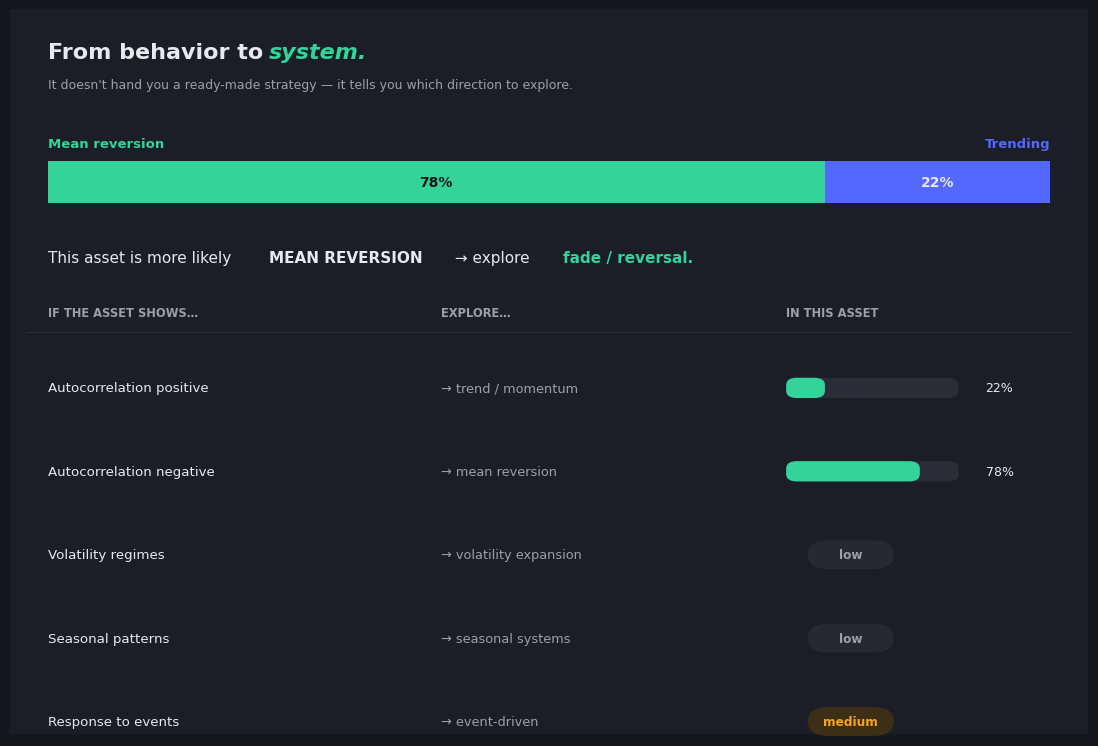


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 7.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.08 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 3.31 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Positive means persistence (momentum).
→ Lag 1: 0.007

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.434

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether certa

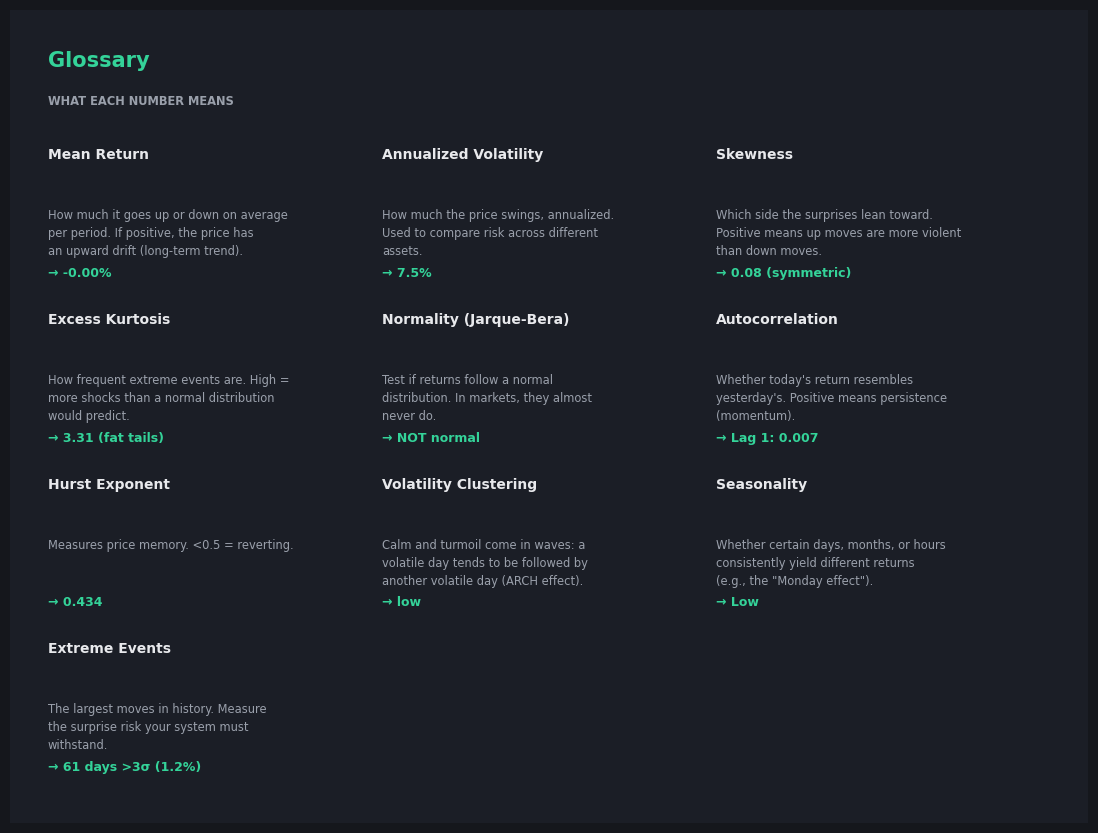




All timeframes analyzed successfully!


In [18]:
# Analyze 15min (raw data)
print("\n" + "="*70)
print("ANALYZING 15MIN TIMEFRAME")
print("="*70)
results_15min = analyze_timeframe_detailed(timeframes['15min'], '15min')

# Analyze 1H
print("\n" + "="*70)
print("ANALYZING 1H TIMEFRAME")
print("="*70)
results_1h = analyze_timeframe_detailed(timeframes['1H'], '1H')

# Analyze 4H
print("\n" + "="*70)
print("ANALYZING 4H TIMEFRAME")
print("="*70)
results_4h = analyze_timeframe_detailed(timeframes['4H'], '4H')

# Analyze 1D
print("\n" + "="*70)
print("ANALYZING 1D TIMEFRAME")
print("="*70)
results_1d = analyze_timeframe_detailed(timeframes['1D'], '1D')

print("\nAll timeframes analyzed successfully!")

## SUMMARY OF RESULTS

In [19]:
summary_df = pd.DataFrame([
    results_15min,
    results_1h,
    results_4h,
    results_1d
])

summary_df = summary_df.set_index('name')

print("\n" + "="*70)
print("SUMMARY OF KEY METRICS ACROSS TIMEFRAMES")
print("="*70)
print(summary_df[['mean_ret', 'vol_ann', 'skew', 'kurt', 'hurst', 'mr_pct', 'trend_pct']])

# Optional: Show full summary if you want all columns
print("\n" + "-"*70)
print("FULL SUMMARY (all metrics)")
print("-"*70)
print(summary_df)


SUMMARY OF KEY METRICS ACROSS TIMEFRAMES
       mean_ret   vol_ann      skew       kurt     hurst  mr_pct  trend_pct
name                                                                       
15min -0.000043  7.538171  0.231418  32.713393  0.497424    57.5       42.5
1H    -0.000173  7.538171  0.059529  13.974930  0.494136    57.5       42.5
4H    -0.000646  7.538171  0.131845  11.003262  0.472001    57.5       42.5
1D    -0.003186  7.538171  0.075811   3.308769  0.433621    77.5       22.5

----------------------------------------------------------------------
FULL SUMMARY (all metrics)
----------------------------------------------------------------------
       mean_ret   vol_ann      skew       kurt      normal  pct_extreme  \
name                                                                      
15min -0.000043  7.538171  0.231418  32.713393  NOT normal     1.615734   
1H    -0.000173  7.538171  0.059529  13.974930  NOT normal     1.795493   
4H    -0.000646  7.538171  0.131

# END OF ANALYSIS

In [20]:
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print("All plots and statistics have been generated.")
print("The reusable functions from utils.py made this analysis concise and portable.")
print("\nSummary of key findings by timeframe:")
print("-"*50)
for idx, row in summary_df.iterrows():
    print(f"{idx}:")
    print(f"  Hurst: {row['hurst']:.3f} → {'Mean Reversion' if row['hurst'] < 0.45 else 'Trending' if row['hurst'] > 0.55 else 'Random Walk'}")
    print(f"  System bias: {row['mr_pct']:.0f}% Mean Reversion / {row['trend_pct']:.0f}% Trending")
    print(f"  Volatility (ann): {row['vol_ann']:.1f}%")
    print(f"  Extreme events (>3σ): {row['pct_extreme']:.2f}% of days")
    print("-"*50)


ANALYSIS COMPLETE
All plots and statistics have been generated.
The reusable functions from utils.py made this analysis concise and portable.

Summary of key findings by timeframe:
--------------------------------------------------
15min:
  Hurst: 0.497 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 7.5%
  Extreme events (>3σ): 1.62% of days
--------------------------------------------------
1H:
  Hurst: 0.494 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 7.5%
  Extreme events (>3σ): 1.80% of days
--------------------------------------------------
4H:
  Hurst: 0.472 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 7.5%
  Extreme events (>3σ): 1.83% of days
--------------------------------------------------
1D:
  Hurst: 0.434 → Mean Reversion
  System bias: 78% Mean Reversion / 22% Trending
  Volatility (ann): 7.5%
  Extreme events (>3σ): 1.16% of days
----------------------------